## 05 Exploratory Data Analysis and Feature Engineering

#### Purpose
- We answer our research questions about **what drives flood claims and lapses**, using the training data only. We have two targets: `CLAIM_IN_TERM` and `LAPSE` (a lapse cancellation during the year or a non-renewal at its end, notebook 04).
- We turn the answers into **features that are known at the start of each policy-year**, and audit them for leakage.
- We prepare the **missing-value and encoding plan** that our models apply in notebooks 06 and 07.

#### Research questions
| # | Question | Main target |
|---|---|---|
| Q1 | When and where do claims happen: how much do a few storms and places drive them? | claim |
| Q2 | Does the property's flood risk (zone, elevation, foundation, building) explain claims? | claim |
| Q3 | Does price, and especially a premium increase under Risk Rating 2.0, drive lapse? | lapse |
| Q4 | Does a mortgage requirement keep policyholders insured? | lapse |
| Q5 | Are new policyholders more likely to lapse than long-standing ones? | lapse |
| Q6 | Do past claims predict future claims, and do they change lapse? | both |
| Q7 | How are claims and cancellations related? | claim, lapse |
| Q8 | Do the neighborhood and economic context (disasters, income, interest rates, CRS) matter? | both |

#### Steps:
- Load the modeling population (notebook 04) and the sources
- Build the features (price, flood risk, coverage, property, tenure, history, context)
- EDA: answer Q1–Q8
- Feature screening: strength of every feature on its own
- Leakage audit: is every feature known at the start of the policy-year?
- Missing-value and encoding plan
- Export the feature table, the feature dictionary and our findings

#### Inputs and outputs
- **In:** `data/processed/modeling_population.parquet` (04), `periods/` and `claim_links/` (03), `policies_clean/`, `disasters_clean.parquet`, `community_clean.parquet`, `acs_clean.parquet`, `fred_monthly.parquet` (02).
- **Out:** `data/processed/features.parquet` (all splits), `docs/feature_dictionary.xlsx`, `docs/feature_plan.csv`, `docs/eda_findings.md`, figures in `reports/`.

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-12

### Section 0. Setup

#### 0.1 Imports and paths
The feature definitions live in `src/features.py` (one list, `FEATURES`, with every feature's group, type, source, definition and when it is known). The EDA tools live in `src/eda.py`. We read their documentation with `help(function_name)`.

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.paths import DOCS, INTERIM, PROCESSED, RAW, REPORTS, ensure_dirs
from src.db import connect, scalar
from src.dq import CleaningLog
from src.population import TARGETS
from src.precip import precip_features_sql
from src.eda import plot_rates, profile, quantile_bins_sql, rate_table, univariate_auc_sql
from src.features import (FEATURES, TARGET_ONLY, acs_features_sql, base_features_sql, community_features_sql,
                          disaster_features_sql, feature_names, fred_features_sql, previous_term_sql,
                          prior_claims_sql, storm_tracks_sql, storm_wind_features_sql, storm_wind_sql)

ensure_dirs()

#### 0.2 Connection and EDA settings

In [2]:
con = connect(db_path=INTERIM / "nfip_05.duckdb", memory_limit="10GB")   # own file: no lock clash with other notebooks
con.execute("SET TimeZone = 'UTC'")

TRAIN = "split = 'train'"     # every analysis in this notebook uses the training split only
MIN_N = 1000                  # we don't read rates from groups smaller than this (too noisy)
log = CleaningLog()

In [3]:
# Step 0.3 Helpers used in every question of Section 3
import re

def explore(feature, keys=("claim", "lapse"), q=None, label=None, save=True):
    '''Rate of each target by one feature (binned into q quantiles if q is given), side by side.'''
    expr = quantile_bins_sql(con, "features", feature, q, TRAIN) if q else feature
    fig, axes = plt.subplots(1, len(keys), figsize=(5.5 * len(keys), 3.6), squeeze=False)
    tables = {}
    for ax, key in zip(axes[0], keys):
        df = rate_table(con, "features", expr, TARGETS[key], where=f"{TRAIN} AND in_pop_{key}", min_n=MIN_N)
        plot_rates(df, f"{TARGETS[key]} by {label or feature}", ax=ax)
        tables[key] = df
    plt.tight_layout()
    if save:   # file name from the label, letters and digits only
        plt.savefig(REPORTS / f"fig_eda_{re.sub(r'[^A-Za-z0-9]+', '_', label or feature).strip('_')}.png", dpi=150)
    plt.show()
    return pd.concat(tables, names=["population"]).droplevel(1)


def by_year(feature, key, q=None):
    '''Stability check: the same rate table, one column per training year.'''
    expr = quantile_bins_sql(con, "features", feature, q, TRAIN) if q else feature
    df = rate_table(con, "features", [expr, "period_year"], TARGETS[key],
                    where=f"{TRAIN} AND in_pop_{key}", min_n=MIN_N)
    return df.pivot(index="group_1", columns="group_2", values="rate_pct")


def lapse_parts(feature, q=None, label=None):
    '''Which part drives lapse? LAPSE and its two parts, by one feature, in the lapse population.'''
    expr = quantile_bins_sql(con, "features", feature, q, TRAIN) if q else feature
    parts = {t: rate_table(con, "features", expr, t, where=f"{TRAIN} AND in_pop_lapse", min_n=MIN_N)
                .set_index("group")["rate_pct"]
             for t in ("LAPSE", "CANCEL_IN_TERM", "NON_RENEWAL")}
    return pd.DataFrame(parts).rename_axis(label or feature)

### Section 1. Load the data
We use **training data only** for every analysis and every decision in this notebook. We build the features for all splits, so the validation and test rows are ready for notebooks 06–08, but we never look at their targets here.

#### 1.1 Load the modeling population and the sources

In [4]:
# Step 1.1a Views
con.execute(f"CREATE OR REPLACE VIEW population AS SELECT * FROM read_parquet('{PROCESSED / 'modeling_population.parquet'}')")
STATES = [r[0] for r in con.execute("SELECT DISTINCT propertyState FROM population ORDER BY 1").fetchall()]
print("states in the population:", STATES)

period_files = ", ".join(f"'{PROCESSED / 'periods' / s}.parquet'" for s in STATES)
link_files = ", ".join(f"'{PROCESSED / 'claim_links' / s}.parquet'" for s in STATES)
con.execute(f"CREATE OR REPLACE VIEW periods AS SELECT * FROM read_parquet([{period_files}])")
con.execute(f"CREATE OR REPLACE VIEW claim_links AS SELECT * FROM read_parquet([{link_files}])")
con.execute(f'''CREATE OR REPLACE VIEW clean_policies AS
                SELECT * FROM read_parquet('{PROCESSED / "policies_clean"}/**/*.parquet', hive_partitioning = true)
                WHERE propertyState IN ({", ".join(f"'{s}'" for s in STATES)})''')
for view, file in [("clean_claims", "claims_clean"), ("clean_disasters", "disasters_clean"),
                   ("clean_community", "community_clean"), ("clean_acs", "acs_clean"),
                   ("clean_fred", "fred_monthly")]:
    con.execute(f"CREATE OR REPLACE VIEW {view} AS SELECT * FROM read_parquet('{PROCESSED / (file + '.parquet')}')")

states in the population: ['AK', 'AL', 'AR', 'AS', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL', 'GA', 'GU', 'HI', 'IA', 'ID', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'ME', 'MI', 'MN', 'MO', 'MP', 'MS', 'MT', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OK', 'OR', 'PA', 'PR', 'RI', 'SC', 'SD', 'TN', 'TX', 'UN', 'UT', 'VA', 'VI', 'VT', 'WA', 'WI', 'WV', 'WY']


In [5]:
# Step 1.1b The population by split
con.sql('''
    SELECT split, MIN(period_year) AS first_year, MAX(period_year) AS last_year, COUNT(*) AS policy_years,
           COUNT(*) FILTER (WHERE in_pop_claim) AS claim_pop,
           COUNT(*) FILTER (WHERE in_pop_lapse) AS lapse_pop
    FROM population GROUP BY 1 ORDER BY first_year
''').df()

,split,first_year,last_year,policy_years,claim_pop,lapse_pop
0,train,2014,2020,27496820,27496820,26758825
1,test,2021,2022,7275717,7275717,7105637
2,valid,2023,2024,5724790,5724790,5621274


In [6]:
# Step 1.1c Tropical-cyclone wind at every policy location (IBTrACS), built once and saved
# IBTrACS gives each storm's centre and maximum wind every 3 hours. For each 0.1-degree policy cell we estimate
# the wind each storm brought there (src/features.py, storm_wind_sql) and keep its peak and date (34+ kt only).
IBTRACS = RAW / "Historical TC Data" / "ibtracs.since1980.list.v04r01.csv"
WIND_FILE = PROCESSED / "storm_wind.parquet"
if not WIND_FILE.exists():
    con.execute(f"CREATE OR REPLACE TEMP TABLE tracks AS {storm_tracks_sql(IBTRACS)}")
    con.execute(f"COPY ({storm_wind_sql('clean_policies', 'tracks')}) TO '{WIND_FILE}' (FORMAT PARQUET)")
    con.execute("DROP TABLE tracks")
con.execute(f"CREATE OR REPLACE VIEW storm_wind AS SELECT * FROM read_parquet('{WIND_FILE}')")
con.sql('''SELECT COUNT(*) AS cell_storm_rows, COUNT(DISTINCT SID) AS storms,
                  COUNT(*) FILTER (WHERE wind_kt >= 64) AS hurricane_force_rows,
                  MIN(wind_date) AS first, MAX(wind_date) AS last
           FROM storm_wind''').df()

,cell_storm_rows,storms,hurricane_force_rows,first,last
0,250821,454,16711,1980-03-15,2024-11-17


In [7]:
# Step 1.1d Rainfall per grid cell (built in notebook 02b): location -> cell, static features, dated features
PRECIP = {"precip_locations": PROCESSED / "precip_locations.parquet",
          "precip_climate": PROCESSED / "precip_climate.parquet",
          "precip_daily": PROCESSED / "precip_daily"}
missing_files = [str(f) for f in PRECIP.values() if not f.exists()]
assert not missing_files, f"run notebook 02b first, missing: {missing_files}"
con.execute(f"CREATE OR REPLACE VIEW precip_locations AS SELECT * FROM read_parquet('{PRECIP['precip_locations']}') WHERE cell_id IS NOT NULL")
con.execute(f"CREATE OR REPLACE VIEW precip_climate AS SELECT * FROM read_parquet('{PRECIP['precip_climate']}')")
con.execute(f"CREATE OR REPLACE VIEW precip_daily AS SELECT * FROM read_parquet('{PRECIP['precip_daily']}/*.parquet')")
con.sql('''SELECT (SELECT COUNT(*) FROM precip_locations) AS locations,
                  (SELECT COUNT(*) FROM precip_climate) AS cells,
                  (SELECT ROUND(MEDIAN(precip_100yr_1d_mm)) FROM precip_climate) AS median_100yr_1d_mm,
                  (SELECT MIN(period_start) FROM precip_daily) AS first_start,
                  (SELECT MAX(period_start) FROM precip_daily) AS last_start''').df()

,locations,cells,median_100yr_1d_mm,first_start,last_start
0,41447,9853,124.0,2014-01-01,2024-08-31


### Section 2. Build the features
Every feature must be known at the **start** of the policy-year. We build them in groups, each as its own view keyed by `period_id`, and join them at the end. The full list, with definitions, is `FEATURES` in `src/features.py`.

| Group | Examples | Source |
|---|---|---|
| Price | premium, price per $1,000 of cover, premium change, Risk Rating 2.0, gap to the full-risk premium | policies |
| Obligation | mortgage requirement (`mandatoryPurchaseFlag`) | policies |
| Flood risk | zone, elevation difference, foundation, basement, CRS class, location | policies |
| Coverage | building and contents coverage, deductibles, insurance to value | policies |
| Property | building age, floors, occupancy group, primary residence, rental | policies |
| Tenure | years since first purchase, new business, years since the property was bought, term number | policies, notebook 03 |
| History | earlier claims (count, amount, recency), gap before this term | claims, notebook 03 |
| Context | flood disasters in the last 12 months, tropical-cyclone wind at the property in earlier years, rainfall (long-run climate of the place, and rain in the 90 days to 3 years before the start), tract income and home value, interest rates, community status | disasters, IBTrACS, NOAA CPC, ACS, FRED, community |

#### 2.1 Price, flood risk, coverage, property and tenure features
These come straight from the policy term and the policy-year (`base_features_sql`).

In [8]:
# Step 2.1 Base features
con.execute(f"CREATE OR REPLACE VIEW f_base AS {base_features_sql('population', 'periods', 'clean_policies')}")
con.sql("SELECT * FROM f_base LIMIT 5").df().T

,0,1,2,3,4
period_id,171779602_0,171796787_0,171798682_0,171812488_0,171824452_0
id,171779602,171796787,171798682,171812488,171824452
period_no,0,0,0,0,0
policy_key,1783647519747558908,321705928504635028,10706681282847856384,7391399393200317429,15282765084700299257
propertyState,AL,AL,AL,AL,AL
...,...,...,...,...,...
year_in_term,0,0,0,0,0
multi_year_term,False,False,False,False,False
start_month,9,2,8,2,12
prev_gap_days,0,0,<NA>,64,0


#### 2.2 Premium and coverage change from the previous term
A premium increase is our main hypothesis for lapse (Q3). We compare each term with the previous term of the same rebuilt policy.

In [9]:
# Step 2.2 Previous term
con.execute(f"CREATE OR REPLACE VIEW f_prev AS {previous_term_sql('f_base', 'clean_policies')}")

#### 2.3 Prior claims history
We count the claims on the same property **before** the policy-year started: number, total paid and recency. We use every claim with the same key, including losses from before the policies data starts (2009). A loss on or after the start date is this policy-year's target, so it is never a feature.

In [10]:
# Step 2.3 Prior claims
con.execute(f"CREATE OR REPLACE VIEW f_hist AS {prior_claims_sql('f_base', 'claim_links')}")

#### 2.4 Context features
- **Disasters:** flood-related declarations in the policy's county (or statewide) in the 12 months before the start, and the days since the last one.
- **Tropical-cyclone wind (IBTrACS):** the estimated wind each earlier storm brought to the property's 0.1° cell (Step 1.1c): the highest wind and the number of 34+ kt and 64+ kt storms in the 10 years before the start, the long-run rate of 64+ kt storms since 1980, and the days since the last 34+ kt wind. Only storms **before** the start count; the wind during the policy-year is part of the outcome.
- **Rainfall (NOAA CPC Unified gauge-based, notebook 02b):** observed daily rain at the property's grid cell (0.25° on the mainland, 0.5° elsewhere). **Static:** the average annual rainfall, the average wettest day and the 100-year 1-day rainfall over 1981–2013, one value per place. **Dated:** the rain in the 90 days before the start, the last 365 days as % of normal, the wettest day and wettest 3 days of the last 365 days, and the days with 50+ mm in the last 3 years. Every window ends the day before the start.
- **ACS:** tract income, home value, age, owner share and population. These are 2018–2022 averages; we note in the leakage audit that they overlap our training years.
- **FRED:** mortgage rate, 10-year Treasury, unemployment, inflation, home prices and fed funds, read **one month before the start** (three months for home prices), so we only use values that were already published.
- **Community:** Emergency Program, sanctions before the start, and the age of the flood map.

In [11]:
# Step 2.4 Context
con.execute(f"CREATE OR REPLACE VIEW f_dis AS {disaster_features_sql('f_base', 'clean_disasters')}")
con.execute(f"CREATE OR REPLACE VIEW f_wind AS {storm_wind_features_sql('f_base', 'storm_wind')}")
con.execute(f"CREATE OR REPLACE VIEW f_precip AS {precip_features_sql('f_base', 'precip_locations', 'precip_climate', 'precip_daily')}")
con.execute(f"CREATE OR REPLACE VIEW f_acs AS {acs_features_sql('f_base', 'clean_acs')}")
con.execute(f"CREATE OR REPLACE VIEW f_fred AS {fred_features_sql('f_base', 'clean_fred')}")
con.execute(f"CREATE OR REPLACE VIEW f_comm AS {community_features_sql('f_base', 'clean_community')}")

#### 2.5 Assemble the feature table
We build the features **one state at a time** and save one file per state in `data/processed/features_by_state/`, then read them back as one view, `features`. Building everything at once ran out of memory (the views are rebuilt inside every join). The loop skips states that are already done, and rebuilds a state whose file is missing a feature listed in `FEATURES`. This is the slowest cell of the notebook.

In [12]:
from src.db import raise_open_file_limit
raise_open_file_limit()     # 256 -> 10240 open files for this kernel

(10240, 10240)

In [13]:
# Step 2.5a Build the features one state at a time, and save one file per state
import time
FEAT_DIR = PROCESSED / "features_by_state"
FEAT_DIR.mkdir(exist_ok=True)
REBUILD = False                      # True: rebuild every state (after changing how a feature is computed)
con.execute("SET threads = 6")       # fewer threads = less memory in use at once

groups = {                           # table name -> SQL that builds it from the state's base table
    "fs_prev": lambda: previous_term_sql("fs_base", "st_policies"),
    "fs_hist": lambda: prior_claims_sql("fs_base", "st_links"),
    "fs_dis":  lambda: disaster_features_sql("fs_base", "clean_disasters"),
    "fs_wind": lambda: storm_wind_features_sql("fs_base", "storm_wind"),
    "fs_precip": lambda: precip_features_sql("fs_base", "precip_locations", "precip_climate", "precip_daily"),
    "fs_acs":  lambda: acs_features_sql("fs_base", "clean_acs"),
    "fs_fred": lambda: fred_features_sql("fs_base", "clean_fred"),
    "fs_comm": lambda: community_features_sql("fs_base", "clean_community"),
}

def has_all_features(path):
    '''True when the state file already has every column in FEATURES (a new feature forces a rebuild).'''
    cols = {r[0] for r in con.execute(f"DESCRIBE SELECT * FROM read_parquet('{path}')").fetchall()}
    return set(feature_names()) <= cols

timings = {}
for st in STATES:
    out = FEAT_DIR / f"{st}.parquet"
    if out.exists() and not REBUILD and has_all_features(out):
        continue
    t0 = time.time()
    con.execute(f"CREATE OR REPLACE VIEW st_pop AS SELECT * FROM population WHERE propertyState = '{st}'")
    con.execute(f"CREATE OR REPLACE VIEW st_periods AS SELECT * FROM read_parquet('{PROCESSED / 'periods' / st}.parquet')")
    con.execute(f"CREATE OR REPLACE VIEW st_links AS SELECT * FROM read_parquet('{PROCESSED / 'claim_links' / st}.parquet')")
    con.execute(f'''CREATE OR REPLACE VIEW st_policies AS SELECT * FROM read_parquet(
                    '{PROCESSED / "policies_clean" / f"propertyState={st}"}/**/*.parquet', hive_partitioning = true)''')

    # 1) the base features once, as a table, so the groups below don't rebuild it
    con.execute(f"CREATE OR REPLACE TABLE fs_base AS {base_features_sql('st_pop', 'st_periods', 'st_policies')}")
    # 2) each group as its own table: one join at a time
    for name, sql in groups.items():
        con.execute(f"CREATE OR REPLACE TABLE {name} AS {sql()}")
    # 3) join the tables and write the state's file (to a temporary name first, so a crash leaves no half file)
    tmp = out.with_suffix(".tmp")
    con.execute(f'''COPY (
        SELECT b.*, {", ".join(f"{n}.* EXCLUDE (period_id)" for n in groups)}
        FROM fs_base b
        {" ".join(f"LEFT JOIN {n} USING (period_id)" for n in groups)}
    ) TO '{tmp}' (FORMAT PARQUET, COMPRESSION ZSTD)''')
    tmp.replace(out)
    timings[st] = round(time.time() - t0, 1)
    print(f"{st}: {timings[st]} s")

for t in ["fs_base", *groups]:
    con.execute(f"DROP TABLE IF EXISTS {t}")
con.execute("CHECKPOINT")            # give the space of the temporary tables back to the database file
print("built", len(timings), "states in", round(sum(timings.values()) / 60, 1), "min")

built 0 states in 0.0 min


In [14]:
# Step 2.5a (check) One view over all state files; no rows added or lost
if scalar(con, "SELECT COUNT(*) FROM duckdb_tables() WHERE table_name = 'features'"):
    con.execute("DROP TABLE features")                # the old all-states table, if an earlier run created it
con.execute(f"CREATE OR REPLACE VIEW features AS SELECT * FROM read_parquet('{FEAT_DIR}/*.parquet')")

missing_states = [s for s in STATES if not (FEAT_DIR / f"{s}.parquet").exists()]
print("states without a feature file:", missing_states or "none")

n_pop, n_feat = scalar(con, "SELECT COUNT(*) FROM population"), scalar(con, "SELECT COUNT(*) FROM features")
print(f"population {n_pop:,} rows, features {n_feat:,} rows, ok={n_pop == n_feat}")   # a join must not add or lose rows

cols = con.sql("DESCRIBE features").df()["column_name"].tolist()
missing = [f for f in feature_names() if f not in cols]
print("features in FEATURES but not built:", missing or "none")

states without a feature file: none
population 40,497,327 rows, features 40,497,327 rows, ok=True
features in FEATURES but not built: none


In [15]:
# Step 2.5b Profile of every feature (training split)
feature_profile = profile(con, "features", feature_names(), TRAIN)
meta = pd.DataFrame(FEATURES, columns=["feature", "group", "kind", "source", "definition", "known_at"])
feature_profile = meta[["feature", "group", "kind"]].merge(feature_profile, on="feature")
feature_profile

,feature,group,kind,missing_pct,distinct,min,max
0,premium,price,num,0.00,23148,-17644,141324
1,policy_cost,price,num,0.00,24548,-19467,167062
2,premium_per_1k_coverage,price,num,0.00,2075300,-81.42131979695432,25495.0
3,rr2_rated,price,flag,0.00,1,false,false
4,full_risk_premium,price,num,50.43,16938,59,38819
...,...,...,...,...,...,...,...
81,home_price_yoy,context,num,0.00,85,3.0999746702258246,10.831012038317
82,fed_funds,context,num,0.00,48,0.05,2.42
83,community_emergency_program,context,flag,0.00,2,false,true
84,community_sanctioned_before,context,flag,0.00,2,false,true


### Section 3. Exploratory data analysis
We understand what drives claims and lapse before we model them.

#### 3.0 Our EDA framework
We answer each question (Q1–Q8) the same way, so our conclusions are comparable and repeatable:

| Step | What we do | Tool |
|---|---|---|
| 1. Ask | We write the question and our hypothesis **before** looking at the numbers, so we test an idea instead of searching for patterns. | markdown |
| 2. Measure | For each group of the feature, the target rate with a 95% confidence interval, and the **lift** (group rate ÷ overall rate). Numbers are cut into 5 quantile bins computed on the training split. | `explore()`, `rate_table()` |
| 3. Check stability | The same rates for each training year. A pattern that appears in one year only is probably a storm, not a driver. | `by_year()` |
| 4. Decide | Keep, transform or drop the feature, and write the reason in "Our findings". | markdown |

**Rules we follow:**
- **Training split only.** We never look at validation or test targets here; they are for the final evaluation.
- **The right population for each target**, from notebook 04 (`in_pop_claim`, `in_pop_lapse`).
- **Which part drives lapse.** `LAPSE` combines a lapse cancellation during the year and a non-renewal at its end. When a feature matters for lapse, `lapse_parts()` shows whether it works through cancellation, non-renewal or both.
- **No group smaller than 1,000 rows** (`MIN_N`): rates of rare events in small groups are noise.
- **Association, not cause.** A higher rate in a group doesn't prove that the feature causes it. For example, older buildings may sit in riskier zones.
- **Overlapping intervals** mean we can't tell the groups apart.

#### 3.1 Q1. When and where do claims happen?
**Question:** How much of the claim volume comes from a few storms and a few places, and does the claim rate change by year and season?

**Our hypothesis:** Most claims come from a handful of named storms, so the claim rate jumps in storm years and is highest for policy-years that cover the hurricane season (June–November).

**What we look at:** claim rate by year and start month; claims by tropical cyclone (the storm whose wind reached the claim's location around the date of loss, from IBTrACS); claim and lapse rate by wind at the property in earlier years; claim rate by county.

**Targets:** `CLAIM_IN_TERM`

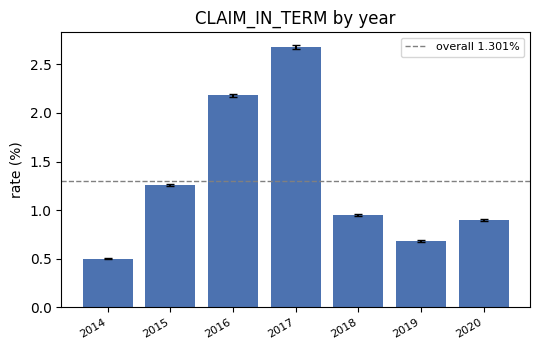

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,2014,4093893,14.89,20541.0,0.502,0.495,0.509,0.39
claim,2015,3939359,14.33,49528.0,1.257,1.246,1.268,0.97
claim,2016,3864017,14.05,84280.0,2.181,2.167,2.196,1.68
claim,2017,3897036,14.17,104315.0,2.677,2.661,2.693,2.06
claim,2018,3928357,14.29,37440.0,0.953,0.944,0.963,0.73
claim,2019,3899882,14.18,26774.0,0.687,0.678,0.695,0.53
claim,2020,3874276,14.09,34944.0,0.902,0.893,0.911,0.69


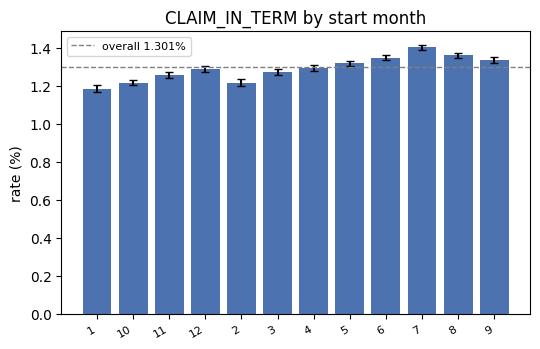

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,1,1571630,5.72,18625.0,1.185,1.168,1.202,0.91
claim,10,2607739,9.48,31678.0,1.215,1.202,1.228,0.93
claim,11,1974297,7.18,24769.0,1.255,1.239,1.270,0.96
claim,12,1806436,6.57,23288.0,1.289,1.273,1.306,0.99
claim,2,1663457,6.05,20251.0,1.217,1.201,1.234,0.94
claim,3,2031804,7.39,25853.0,1.272,1.257,1.288,0.98
claim,4,2116884,7.70,27357.0,1.292,1.277,1.308,0.99
claim,5,2380944,8.66,31380.0,1.318,1.304,1.333,1.01
claim,6,2834440,10.31,38203.0,1.348,1.334,1.361,1.04


In [16]:
# Step 3.1a Claim rate by year and by start month
display(explore("period_year", keys=("claim",), label="year"))
explore("start_month", keys=("claim",), label="start month")

In [17]:
# Step 3.1b Claims by storm: each training-year claim is matched to the tropical cyclone that brought the
# strongest wind (34+ kt) to the claim's 0.1-degree cell, from 3 days before to 10 days after the date of loss
train_years = [r[0] for r in con.execute(f"SELECT DISTINCT period_year FROM population WHERE {TRAIN} ORDER BY 1").fetchall()]
states_sql = ", ".join(f"'{s}'" for s in STATES)
storms = con.sql(f'''
    WITH cl AS (
        SELECT id, CAST(latitude AS DOUBLE) AS lat, CAST(longitude AS DOUBLE) AS lon, loss_date
        FROM clean_claims
        WHERE state IN ({states_sql}) AND YEAR(loss_date) IN ({", ".join(str(y) for y in train_years)})
    ),
    m AS (
        SELECT cl.id, w.storm_name, w.season, w.wind_kt
        FROM cl LEFT JOIN storm_wind w
          ON w.latitude = cl.lat AND w.longitude = cl.lon
         AND cl.loss_date BETWEEN w.wind_date - INTERVAL 3 DAY AND w.wind_date + INTERVAL 10 DAY
        QUALIFY ROW_NUMBER() OVER (PARTITION BY cl.id ORDER BY w.wind_kt DESC NULLS LAST) = 1
    )
    SELECT COALESCE(storm_name || ' (' || season || ')', '(no tropical-cyclone wind)') AS storm,
           COUNT(*) AS claims,
           ROUND(MEDIAN(wind_kt)) AS median_wind_kt_at_claim,
           ROUND(100 * AVG(CASE WHEN wind_kt >= 64 THEN 1.0 ELSE 0 END), 1) AS pct_claims_hurricane_force
    FROM m GROUP BY ALL ORDER BY claims DESC
''').df()
storms["share_pct"] = (100 * storms["claims"] / storms["claims"].sum()).round(2)
storms["cumulative_pct"] = storms["share_pct"].cumsum().round(2)
storms.head(15)

,storm,claims,median_wind_kt_at_claim,pct_claims_hurricane_force,share_pct,cumulative_pct
0,(no tropical-cyclone wind),206855,NaN,0.0,52.39,52.39
1,HARVEY (2017),88854,40.0,7.4,22.50,74.89
2,IRMA (2017),26317,46.0,37.8,6.67,81.56
3,MATTHEW (2016),21793,70.0,60.5,5.52,87.08
4,FLORENCE (2018),16569,60.0,38.1,4.20,91.28
5,SALLY (2020),7859,92.0,85.2,1.99,93.27
6,MICHAEL (2018),5264,106.0,75.2,1.33,94.60
7,ETA (2020),3244,39.0,0.0,0.82,95.42
8,ISAIAS (2020),2990,58.0,41.8,0.76,96.18
9,IMELDA (2019),2835,35.0,0.0,0.72,96.90


In [18]:
# Step 3.1c Claim rate by county (largest 15 counties)
county = rate_table(con, "features", "county_fips", "CLAIM_IN_TERM", where=f"{TRAIN} AND in_pop_claim", min_n=MIN_N)
county.sort_values("n", ascending=False).head(15)

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
1068,48201,1894832,6.89,63881.0,3.371,3.346,3.397,2.59
184,12086,1163412,4.23,5297.0,0.455,0.443,0.468,0.35
157,12011,949379,3.45,3627.0,0.382,0.370,0.395,0.29
427,22051,713669,2.60,1777.0,0.249,0.238,0.261,0.19
191,12099,631389,2.30,807.0,0.128,0.119,0.137,0.10
178,12071,600924,2.19,2235.0,0.372,0.357,0.388,0.29
435,22071,517327,1.88,2636.0,0.510,0.491,0.529,0.39
193,12103,489700,1.78,1770.0,0.361,0.345,0.379,0.28
1060,48167,402049,1.46,9023.0,2.244,2.199,2.290,1.72
973,45019,401145,1.46,4820.0,1.202,1.168,1.236,0.92


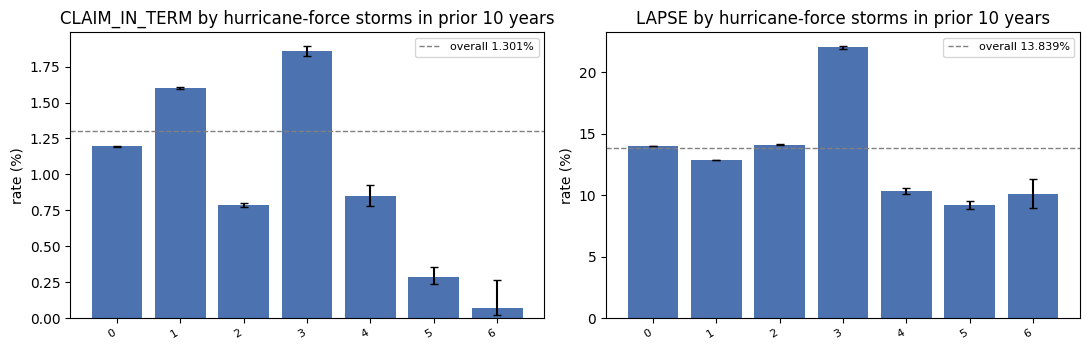

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,0,16764658,60.97,200451.0,1.196,1.190,1.201,0.92
claim,1,8214975,29.88,131406.0,1.600,1.591,1.608,1.23
claim,2,1834608,6.67,14446.0,0.787,0.775,0.800,0.61
claim,3,585700,2.13,10886.0,1.859,1.824,1.894,1.43
claim,4,64030,0.23,544.0,0.850,0.781,0.924,0.65
claim,5,30119,0.11,87.0,0.289,0.234,0.356,0.22
claim,6,2730,0.01,2.0,0.073,0.020,0.267,0.06
lapse,0,16320805,60.99,2288289.0,14.021,14.004,14.038,1.01
lapse,1,7985678,29.84,1027804.0,12.871,12.847,12.894,0.93


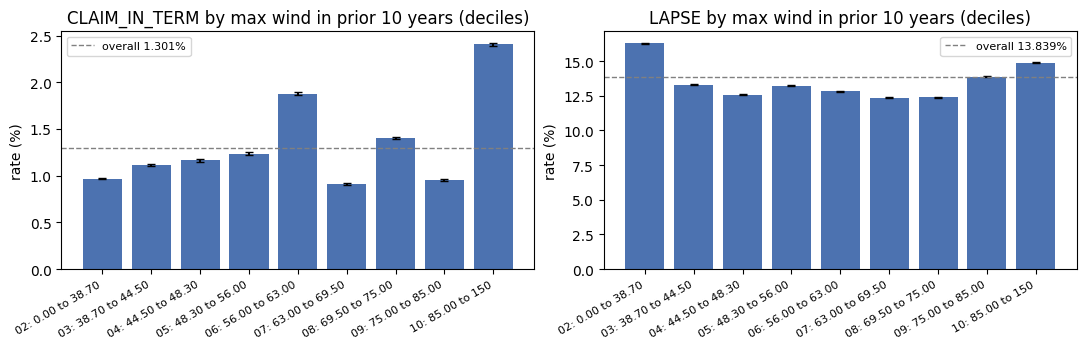

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,02: 0.00 to 38.70,5489212,19.96,53202.0,0.969,0.961,0.977,0.74
claim,03: 38.70 to 44.50,2729971,9.93,30482.0,1.117,1.104,1.129,0.86
claim,04: 44.50 to 48.30,2765489,10.06,32150.0,1.163,1.150,1.175,0.89
claim,05: 48.30 to 56.00,2759312,10.04,34101.0,1.236,1.223,1.249,0.95
claim,06: 56.00 to 63.00,2473528,9.00,46418.0,1.877,1.860,1.894,1.44
claim,07: 63.00 to 69.50,3012566,10.96,27378.0,0.909,0.898,0.920,0.70
claim,08: 69.50 to 75.00,2146451,7.81,30122.0,1.403,1.388,1.419,1.08
claim,09: 75.00 to 85.00,2978246,10.83,28328.0,0.951,0.940,0.962,0.73
claim,10: 85.00 to 150,3142045,11.43,75641.0,2.407,2.390,2.424,1.85


In [19]:
# Step 3.1d Claim and lapse rate by tropical-cyclone wind at the property before the start
display(explore("hurricane_wind_storms_10y", label="hurricane-force storms in prior 10 years"))
explore("max_wind_kt_10y", q=10, label="max wind in prior 10 years (deciles)")

> **Our findings (Q1):** 
A few storms drive a large share of claims, but most claims are not from tropical cyclones. 47.6% of training claims had tropical-cyclone wind (34+ kt) at the property around the date of loss. Harvey alone accounts for 22.5% of claims, and Harvey, Irma, Matthew and Florence together for 38.9%. The other 52.4% had no tropical-cyclone wind: they come from other floods (heavy rain, rivers, snowmelt), which rainfall features may explain better than wind.
Wind is not the same as flood. Harvey’s claims had a median wind of only 40 kt (7.4% hurricane force), because the flooding came from rain. Michael and Laura (about 106–107 kt) were mostly hurricane force.
> 
>The claim rate depends strongly on the year, and very little on the start month. It ranges from 0.50% in 2014 (lift 0.39) to 2.68% in 2017 (lift 2.06), following the storm years 2016–2017. By start month it only ranges from 1.19% to 1.40% (lift 0.91–1.08), because every policy-year covers a full hurricane season.
> 
> **Feature decision:** We suggest to retain these features as indicators of extreme hurricane and precipitation could help predict claims. 

#### 3.2 Q2. Does the property's flood risk explain claims?
**Question:** Do flood zone, elevation, foundation, basement and building age separate high-risk from low-risk policy-years?

**Our hypothesis:** Claims are more likely in zones A and V, for buildings below the base flood elevation, with basements or on slabs, and for older (pre-FIRM) buildings.

**What we look at:** claim rate by zone group, SFHA, elevation difference, elevated building, foundation, basement, building age, floors.

**Targets:** `CLAIM_IN_TERM`

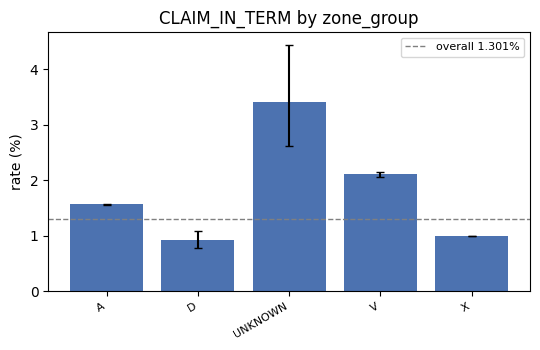

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,A,13836652,50.32,217306.0,1.571,1.564,1.577,1.21
claim,D,15156,0.06,140.0,0.924,0.783,1.089,0.71
claim,UNKNOWN,1551,0.01,53.0,3.417,2.622,4.443,2.63
claim,V,354349,1.29,7461.0,2.106,2.059,2.153,1.62
claim,X,13289112,48.33,132862.0,1.000,0.994,1.005,0.77


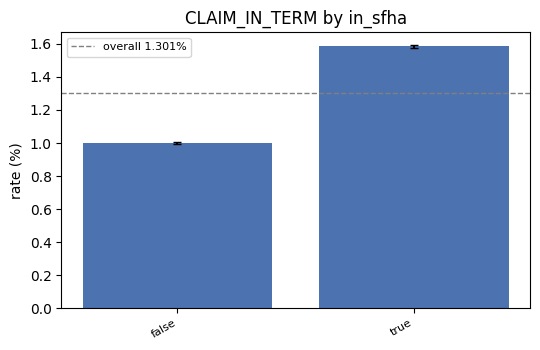

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,false,13305819,48.39,133055.0,1.000,0.995,1.005,0.77
claim,true,14191001,51.61,224767.0,1.584,1.577,1.590,1.22


In [20]:
# Step 3.2a Zone and SFHA
display(explore("zone_group", keys=("claim",)))
explore("in_sfha", keys=("claim",))

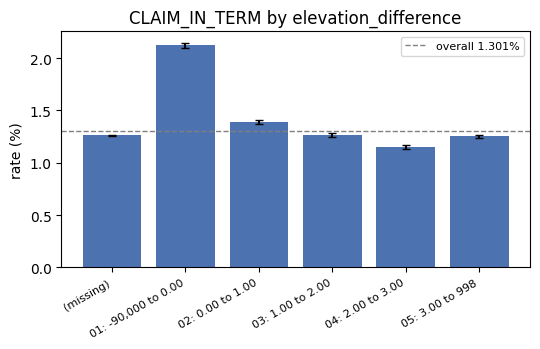

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,(missing),18279828,66.48,230964.0,1.263,1.258,1.269,0.97
claim,"01: -90,000 to 0.00",1230098,4.47,26102.0,2.122,2.097,2.148,1.63
claim,02: 0.00 to 1.00,1566548,5.70,21761.0,1.389,1.371,1.408,1.07
claim,03: 1.00 to 2.00,2146416,7.81,27146.0,1.265,1.250,1.280,0.97
claim,04: 2.00 to 3.00,1672037,6.08,19241.0,1.151,1.135,1.167,0.88
claim,05: 3.00 to 998,2601893,9.46,32608.0,1.253,1.240,1.267,0.96


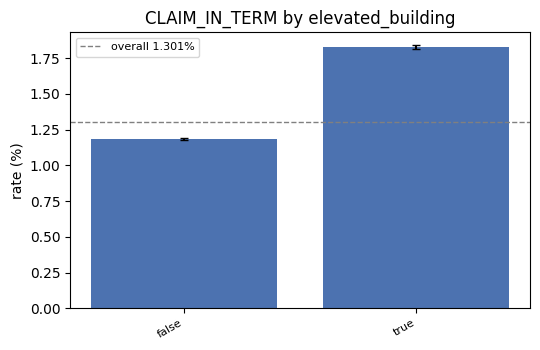

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,false,22455125,81.66,265732.0,1.183,1.179,1.188,0.91
claim,true,5041695,18.34,92090.0,1.827,1.815,1.838,1.40


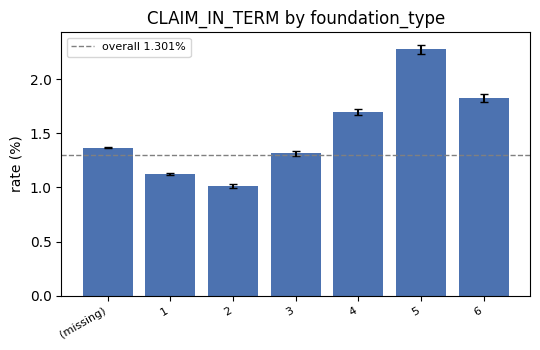

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,(missing),13866982,50.43,189745.0,1.368,1.362,1.374,1.05
claim,1,9219664,33.53,103465.0,1.122,1.115,1.129,0.86
claim,2,1302121,4.74,13167.0,1.011,0.994,1.029,0.78
claim,3,1237252,4.50,16259.0,1.314,1.294,1.334,1.01
claim,4,906557,3.30,15368.0,1.695,1.669,1.722,1.30
claim,5,496801,1.81,11299.0,2.274,2.233,2.316,1.75
claim,6,467443,1.70,8519.0,1.822,1.785,1.861,1.40


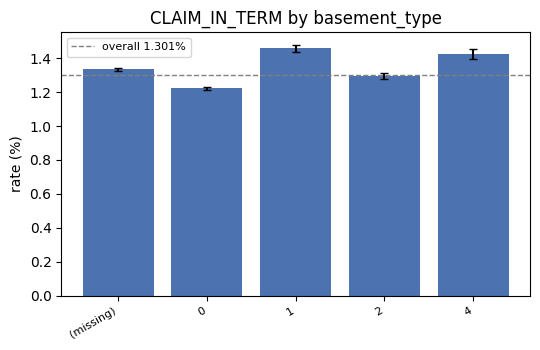

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,(missing),14224064,51.73,189579.0,1.333,1.327,1.339,1.02
claim,0,9280223,33.75,113440.0,1.222,1.215,1.229,0.94
claim,1,1457134,5.30,21245.0,1.458,1.439,1.478,1.12
claim,2,1968205,7.16,25479.0,1.295,1.279,1.310,0.99
claim,4,567194,2.06,8079.0,1.424,1.394,1.456,1.09


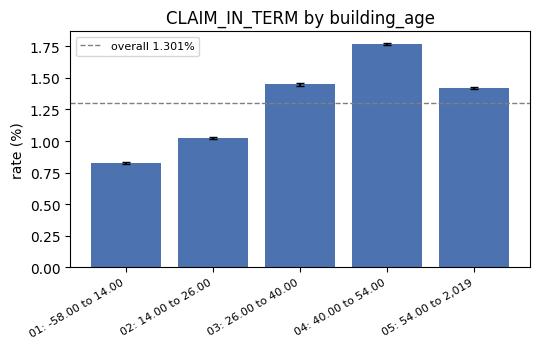

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,01: -58.00 to 14.00,5124923,18.64,42251.0,0.824,0.817,0.832,0.63
claim,02: 14.00 to 26.00,5545407,20.17,56635.0,1.021,1.013,1.030,0.78
claim,03: 26.00 to 40.00,5785819,21.04,83840.0,1.449,1.439,1.459,1.11
claim,04: 40.00 to 54.00,5257469,19.12,92999.0,1.769,1.758,1.780,1.36
claim,"05: 54.00 to 2,019",5783202,21.03,82097.0,1.420,1.410,1.429,1.09


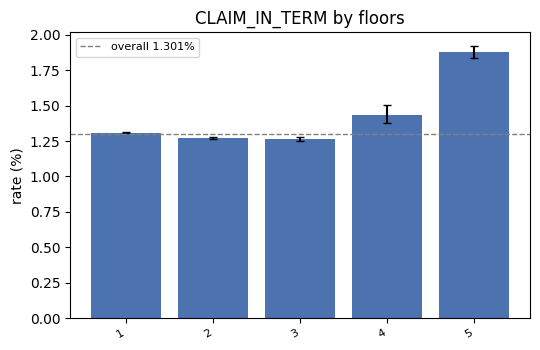

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,1,15747928,57.27,206212.0,1.309,1.304,1.315,1.01
claim,2,9089390,33.06,115452.0,1.270,1.263,1.277,0.98
claim,3,2154801,7.84,27269.0,1.265,1.251,1.281,0.97
claim,4,133169,0.48,1914.0,1.437,1.375,1.503,1.10
claim,5,370740,1.35,6962.0,1.878,1.835,1.922,1.44


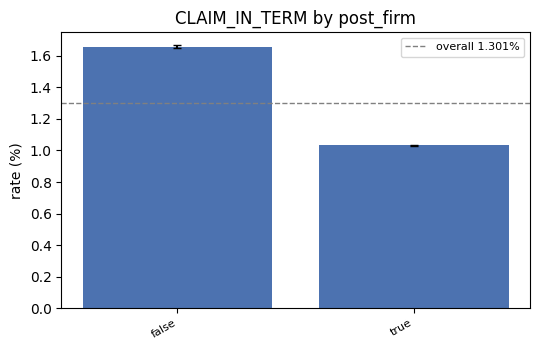

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,false,11839023,43.06,196292.0,1.658,1.651,1.665,1.27
claim,true,15657797,56.94,161530.0,1.032,1.027,1.037,0.79


In [21]:
# Step 3.2b Elevation and building
for f, q in [("elevation_difference", 5), ("elevated_building", None), ("foundation_type", None),
             ("basement_type", None), ("building_age", 5), ("floors", None), ("post_firm", None)]:
    display(explore(f, keys=("claim",), q=q))

In [22]:
# Step 3.2c Stability: claim rate by zone group in each training year
by_year("zone_group", "claim")

group_2,2014,2015,2016,2017,2018,2019,2020
group_1,,,,,,,
A,0.501,1.585,2.772,3.013,1.225,0.771,1.187
D,0.558,0.689,1.555,1.834,0.591,0.662,0.456
V,0.374,0.908,2.727,3.859,2.848,1.087,3.096
X,0.506,0.879,1.509,2.308,0.649,0.598,0.588


> **Our findings (Q2):** 
> 
> The flood zone separates risk, and the pattern holds in every year after 2014.
> - Policy-years rated in zone V have a claim rate of 2.11% (lift 1.62) and zone A 1.57% (lift 1.21), against 1.00% in zone X (lift 0.77) and 0.92% in zone D.
> - Inside the Special Flood Hazard Area (A or V) the rate is 1.58% against 1.00% outside: 1.6 times higher.
Zone X still matters: it holds 48% of policy-years and 37% of all claims (132,862 of 357,822). A low-risk zone is not no-risk.
> - By year (3.2c), zone A is above zone X in every year from 2015 to 2020. Zone V is the highest in the storm years (3.86% in 2017, 3.10% in 2020). In calm 2014 all zones are close to 0.5%.
> 
> Being below the base flood elevation (BFE) raises the claim rate; height above it adds little. Buildings with the lowest floor at or below the BFE have a 2.12% rate (lift 1.63). From 0 ft above it, the rate falls to 1.39%, then to about 1.15–1.27% from 1 ft up. Two-thirds of policy-years (66%) have no elevation difference, and their rate (1.26%) is close to the average.
> - Older buildings and pre-FIRM buildings claim more.
> - Pre-FIRM buildings (built before the community’s first flood map) have 1.66% against 1.03% for post-FIRM: 1.6 times higher.
> 
> The rate rises with building age, from 0.82% (under 14 years, lift 0.63) to 1.77% (40–54 years, lift 1.36), then drops to 1.42% for the oldest group (54+).
> - Elevated buildings claim more, not less, because of where they are.
> - Elevated buildings have 1.83% against 1.18% (lift 1.40).
> - Elevated foundations on posts, piles or piers have the highest rates: 2.27% with an enclosure (lift 1.75) and 1.70% without.
> - These buildings are elevated because they are in high-risk coastal areas. The zone and location drive the rate, not the elevation itself.
> 
> Our hypothesis about basements and slabs is not supported.
> - Basement foundations have the lowest rate (1.01%, lift 0.78), and slab foundations are also below average (1.12%, lift 0.86).
> - The basement type adds little (lift 0.94–1.12).
> - Basements are more common inland, away from the coast, which likely explains the low rate.
> - Mobile homes stand out. Manufactured (mobile) homes have 1.88% (lift 1.44), and split-level homes 1.44%. One, two and three or more floors are all about 1.27–1.31%.
> 
> **Feature decision:** Keep all features.

#### 3.3 Q3. Does price, and a premium increase, drive lapse?
**Question:** Are policyholders with higher premiums, larger premium increases, or a large gap to their full-risk premium more likely to cancel or not renew?

**Our hypothesis:** Lapse rises with the premium increase from the previous term, and is higher under Risk Rating 2.0 for policyholders still far below their full-risk premium (more increases to come).

**What we look at:** lapse rates (and their two parts) by premium, price per $1,000 of cover, premium change, Risk Rating 2.0 and discount to full risk.

**Targets:** `LAPSE` (parts: `CANCEL_IN_TERM`, `NON_RENEWAL`)

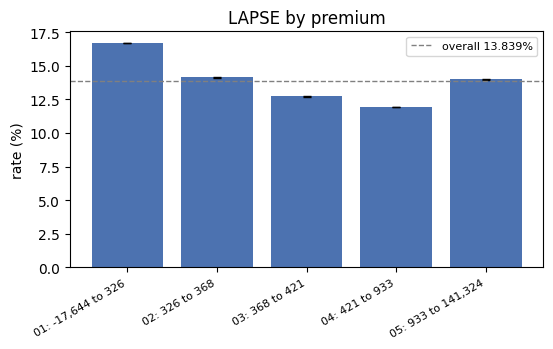

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,"01: -17,644 to 326",4832840,18.06,806597.0,16.690,16.657,16.723,1.21
lapse,02: 326 to 368,5698820,21.30,806070.0,14.145,14.116,14.173,1.02
lapse,03: 368 to 421,5531199,20.67,703983.0,12.727,12.700,12.755,0.92
lapse,04: 421 to 933,5356849,20.02,639096.0,11.930,11.903,11.958,0.86
lapse,"05: 933 to 141,324",5339117,19.95,747479.0,14.000,13.971,14.030,1.01


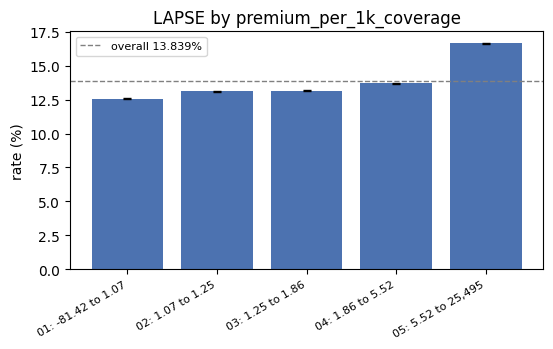

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,01: -81.42 to 1.07,5684352,21.24,714913.0,12.577,12.550,12.604,0.91
lapse,02: 1.07 to 1.25,4883133,18.25,639810.0,13.102,13.073,13.132,0.95
lapse,03: 1.25 to 1.86,5342407,19.97,703483.0,13.168,13.139,13.197,0.95
lapse,04: 1.86 to 5.52,5507831,20.58,754849.0,13.705,13.676,13.734,0.99
lapse,"05: 5.52 to 25,495",5340899,19.96,890074.0,16.665,16.634,16.697,1.20


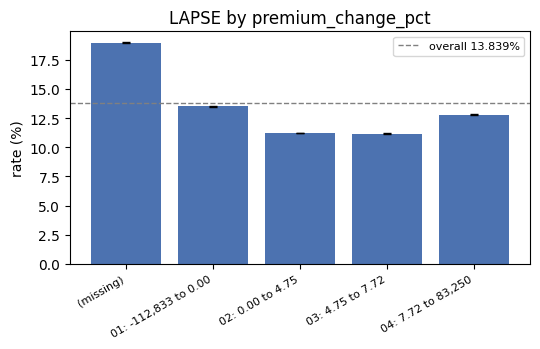

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,(missing),7346242,27.45,1393392.0,18.967,18.939,18.996,1.37
lapse,"01: -112,833 to 0.00",3058179,11.43,413604.0,13.525,13.486,13.563,0.98
lapse,02: 0.00 to 4.75,8596528,32.13,966464.0,11.242,11.221,11.264,0.81
lapse,03: 4.75 to 7.72,3871113,14.47,432408.0,11.170,11.139,11.202,0.81
lapse,"04: 7.72 to 83,250",3886763,14.53,497357.0,12.796,12.763,12.829,0.92


,LAPSE,CANCEL_IN_TERM,NON_RENEWAL
premium_change_pct,,,
(missing),18.967,0.102,18.964
"01: -112,833 to 0.00",13.525,0.130,13.522
02: 0.00 to 4.75,11.242,0.106,11.240
03: 4.75 to 7.72,11.170,0.155,11.160
"04: 7.72 to 83,250",12.796,0.254,12.789


In [23]:
# Step 3.3a Price level and change
for f, q in [("premium", 5), ("premium_per_1k_coverage", 5), ("premium_change_pct", 5)]:
    display(explore(f, keys=("lapse",), q=q))
lapse_parts("premium_change_pct", q=5)

Here are your 3.3a findings, from the saved outputs. I also used 3.3c, because it's the stability check for the premium change. The overall lapse rate in the training population is **13.84%**.

> **Our findings (Q3, price level and change):**
> 1. **The cheapest policies lapse the most.**
>    - The lowest premium group (up to $326) has a lapse rate of **16.69%** (lift 1.21).
>    - The rate falls to **11.93%** for premiums of $421–933 (lift 0.86), then rises again to 14.00% for the most expensive group (over $933).
>    - Cheap policies are mostly low-risk properties (zone X, preferred-risk rates) that are not required by a mortgage, so dropping them is easy.
> 2. **The price per $1,000 of cover works the other way: the more expensive the cover, the higher the lapse.** It rises steadily from **12.58%** in the lowest group (lift 0.91) to **16.67%** in the highest (over $5.52 per $1,000, lift 1.20). Policyholders who pay a lot for each dollar of cover leave more often.
> 3. **A large premium increase raises lapse, and the pattern holds in every year.**
>    - Among renewals, policyholders with increases above **7.7%** lapse at **12.80%**, against about **11.2%** for increases up to 7.7%. That's about 1.6 points, or 14% more.
>    - In every year from 2015 to 2020, the largest-increase group has the highest lapse among renewals with an increase. For example, **20.95% against 16.46%** in 2015, and **9.72% against 7.17%** in 2019 (3.3c).
>    - Policyholders whose premium **fell** also lapse more (13.53%), though not in every year. A lower premium may reflect reduced cover before leaving.
> 4. **The biggest group is the one with no premium change (27% of policy-years), with the highest lapse: 18.97% (lift 1.37).** These have no previous term to compare with, so they are mostly **first-year policies**. The high rate is a new-business effect, not a price effect (Q5). For 2014 every value is missing (3.3c), so the 2014 rate sits entirely in this group.
> 5. **Lapse here is almost entirely non-renewal.** Cancellations during the term are at most **0.25%** in every group. They do rise with the premium increase (from 0.11% to 0.25%), but they're too rare to matter.
>
> **Feature decision:**
> - **`premium`: keep.** The effect is U-shaped, so for logistic regression we use bins or a spline. Negative premiums (down to −$17,644) are data errors or refunds; we set them to missing.
> - **`premium_per_1k_coverage`: keep.** The lowest and highest values (−$81 and $25,495 per $1,000) are not plausible; we cap the top at the 99th percentile and set negative values to missing.
> - **`premium_change_pct`: keep, transform.**
>   - Add a flag for "no previous term", which carries most of the signal, and keep the change itself for renewals.
>   - Cap the extreme values (−112,833% to 83,250%), for example at the 1st and 99th percentiles.
>   - We should also check why every 2014 value is missing, before trusting the flag in 2014.

**Two things in 3.3b you should look at before writing Q3's feature decision:**
- **`rr2_rated` is false for every training policy-year.** Risk Rating 2.0 started in October 2021, after our training years (2014–2020). The model can't learn anything from it, so **drop it** as a feature. Mention the change of rating system as a limitation: it appears only in the test (2021–2022) and validation splits.
- **`discount_to_full_risk` looks like leakage.** Where it's **missing** (49%), the lapse rate is **27.6%**; where it's filled, the lapse rate is **0.55–0.63%**, in every group. A real price effect wouldn't do that: it suggests the full-risk premium is only filled in for policies that stayed, so whether it's filled says whether the policy lapsed. **Don't use `discount_to_full_risk` or `full_risk_premium` until it's checked.** For example, look at the share filled in by `period_year` and by `LAPSE`. I can write that check for you.

/opt/homebrew/Cellar/jupyterlab/4.5.6_2/libexec/lib/python3.14/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


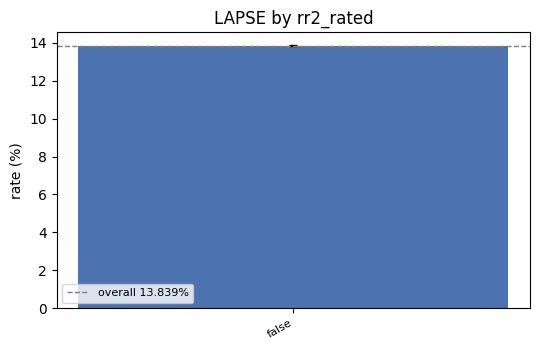

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,false,26758802,100.0,3703220.0,13.839,13.826,13.852,1.0


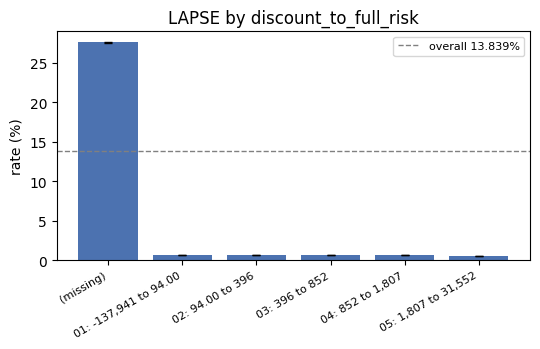

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,(missing),13129113,49.06,3620882.0,27.579,27.555,27.603,1.99
lapse,"01: -137,941 to 94.00",2719080,10.16,16773.0,0.617,0.608,0.626,0.04
lapse,02: 94.00 to 396,2729406,10.20,17118.0,0.627,0.618,0.637,0.05
lapse,03: 396 to 852,2725652,10.19,17189.0,0.631,0.621,0.640,0.05
lapse,"04: 852 to 1,807",2729590,10.20,16213.0,0.594,0.585,0.603,0.04
lapse,"05: 1,807 to 31,552",2725984,10.19,15050.0,0.552,0.543,0.561,0.04


In [24]:
# Step 3.3b Risk Rating 2.0 and the gap to the full-risk premium
display(explore("rr2_rated", keys=("lapse",)))
explore("discount_to_full_risk", keys=("lapse",), q=5)

In [25]:
# Step 3.3c Stability: lapse by premium change in each training year
by_year("premium_change_pct", "lapse", q=5)

group_2,2014,2015,2016,2017,2018,2019,2020
group_1,,,,,,,
(missing),15.801,28.999,22.530,22.226,21.229,19.295,21.944
"01: -112,833 to 0.00",NaN,15.003,15.058,9.494,9.700,9.547,11.985
02: 0.00 to 4.75,NaN,16.460,12.886,10.675,10.052,7.171,8.689
03: 4.75 to 7.72,NaN,17.624,13.938,11.274,10.608,8.802,11.129
"04: 7.72 to 83,250",NaN,20.954,17.090,13.993,13.054,9.720,12.266


This is the full Q3 block, combining 3.3a, 3.3b and 3.3c, ready to paste into the "Our findings (Q3)" cell. The overall lapse rate in training is **13.84%**.

> **Our findings (Q3):**
> 1. **A large premium increase raises lapse, and the pattern holds in every year.**
>    - Among renewals, policyholders with an increase above **7.7%** lapse at **12.80%**, against about **11.2%** for increases up to 7.7%. That's 1.6 points, or 14% more.
>    - In every year from 2015 to 2020, the largest-increase group has the highest lapse among renewals with an increase. For example, **20.95% against 16.46%** in 2015, **17.09% against 12.89%** in 2016, and **9.72% against 7.17%** in 2019 (3.3c).
>    - Policyholders whose premium **fell** also lapse more (13.53%), but not in every year. A lower premium may reflect reduced cover before leaving.
> 2. **The highest lapse is in policy-years with no premium change: 18.97% (lift 1.37, 27% of policy-years).** These have no previous term to compare with, so they are mostly **first-year policies**. This is a new-business effect, not a price effect (see Q5). Every 2014 value is missing, so all of 2014 sits in this group.
> 3. **The price level matters in two directions.**
>    - By premium, the **cheapest** policies (up to $326) lapse the most: **16.69%** (lift 1.21), against **11.93%** for $421–933 (lift 0.86). The effect is U-shaped, rising again to 14.00% above $933. Cheap policies are mostly low-risk properties that a mortgage doesn't require, so dropping them is easy.
>    - By price per $1,000 of cover, lapse rises steadily from **12.58%** (lift 0.91) to **16.67%** (lift 1.20). Policyholders who pay more for each dollar of cover leave more often.
> 4. **Lapse is almost entirely non-renewal.** Cancellations during the term are at most **0.25%** in every price group. They rise with the premium increase (0.11% to 0.25%), but they're too rare to drive the target.
> 5. **We cannot test the Risk Rating 2.0 part of our hypothesis on the training data.**
>    - `rr2_rated` is false for every training policy-year: Risk Rating 2.0 started in October 2021, after our training years.
>    - The gap to the full-risk premium (`discount_to_full_risk`) shows a pattern that is not a price effect. Where it is **missing** (49%), lapse is **27.6%** (lift 1.99); where it is filled, lapse is **0.55–0.63%** in every group (lift 0.04). Whether the value is filled seems to depend on whether the policy stayed, which would leak the outcome.
>
> **Our hypothesis:** partly supported. Lapse does rise with the premium increase in every year, but the effect is moderate (about 14%). New business and cheap, low-risk policies matter more. The Risk Rating 2.0 part can't be tested on the training years.
>
> **Feature decision:**
> - **`premium_change_pct`: keep, transform.**
>   - Add a flag for "no previous term", which carries most of the signal, and keep the change itself for renewals.
>   - Cap the extreme values (−112,833% to 83,250%) at the 1st and 99th percentiles.
>   - We still need to check why every 2014 value is missing.
> - **`premium`: keep.** The effect is U-shaped, so for logistic regression we use bins or a spline. Negative premiums (down to −$17,644) become missing.
> - **`premium_per_1k_coverage`: keep.** Cap the top at the 99th percentile (the highest value is $25,495 per $1,000), and set negative values to missing.
> - **`rr2_rated`: drop.** It is constant in training. We note the change of rating system as a limitation: it appears only in the test (2021–2022) and validation (2023–2024) years, so we watch for drift there.
> - **`discount_to_full_risk` and `full_risk_premium`: hold back.** We check the share filled in by year and by lapse before using either; if being filled depends on the outcome, we drop both.

The last decision depends on that check. If you'd like, I can write the check query so you can settle it before finalizing Q3.

#### 3.4 Q4. Does a mortgage requirement keep policyholders insured?
**Question:** Do policyholders whose lender requires flood insurance cancel or lapse less often?

**Our hypothesis:** Mandatory-purchase policies lapse much less, except when the mortgage is paid off or the lender stops requiring it (codes 52 and 28).

**What we look at:** lapse rates (and their two parts) by `mandatory_purchase`, and the same split by tenure.

**Targets:** `LAPSE` (parts: `CANCEL_IN_TERM`, `NON_RENEWAL`)

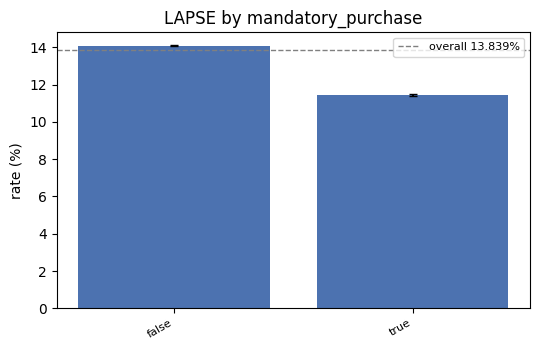

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,false,24231553,90.56,3414030.0,14.089,14.075,14.103,1.02
lapse,true,2527272,9.44,289195.0,11.443,11.404,11.482,0.83


,LAPSE,CANCEL_IN_TERM,NON_RENEWAL
mandatory_purchase,,,
false,14.089,0.125,14.085
true,11.443,0.239,11.438


In [26]:
# Step 3.4a Mandatory purchase
display(explore("mandatory_purchase", keys=("lapse",)))
lapse_parts("mandatory_purchase")

In [27]:
# Step 3.4b Mandatory purchase by tenure (lapse)
rate_table(con, "features",
           ["mandatory_purchase", quantile_bins_sql(con, "features", "tenure_years", 4, TRAIN)],
           "LAPSE", where=f"{TRAIN} AND in_pop_lapse", min_n=MIN_N
          ).pivot(index="group_2", columns="group_1", values="rate_pct")

group_1,false,true
group_2,,
01: -12.56 to 1.00,19.358,14.170
02: 1.00 to 4.00,16.326,10.460
03: 4.00 to 9.00,12.683,8.260
"04: 9.00 to 2,019",9.277,7.677


Here are your Q4 findings, from the saved outputs of 3.4a and 3.4b. The overall lapse rate in training is **13.84%**.

> **Our findings (Q4):**
> 1. **Policies required by a mortgage lapse less, but not much less.** Mandatory-purchase policy-years lapse at **11.44%** (lift 0.83), against **14.09%** for voluntary ones (lift 1.02). That's **19% lower**, a gap of 2.6 points. Only **9.4%** of policy-years are flagged as mandatory.
> 2. **The gap is larger within each tenure group: 27–36% lower.** Lapse falls with tenure for both groups, and mandatory policies are lower in every tenure group (3.4b):
>
>    | Years since first purchase | Voluntary | Mandatory | Mandatory vs voluntary |
>    |---|---|---|---|
>    | under 1 | 19.36% | 14.17% | 27% lower |
>    | 1 to 4 | 16.33% | 10.46% | 36% lower |
>    | 4 to 9 | 12.68% | 8.26% | 35% lower |
>    | 9 or more | 9.28% | 7.68% | 17% lower |
>
>    The overall gap (19%) is smaller than the gap within each tenure group, because mandatory policies are more often recent ones, which lapse more. Mortgages are usually tied to recent purchases. So we read the mortgage effect together with tenure.
> 3. **The gap narrows for long-held policies.** It falls from about 5–6 points in the first 9 years to **1.6 points after 9 years**. That fits our hypothesis: over time, mortgages are paid off or refinanced, and the requirement no longer holds.
> 4. **Mandatory policies cancel during the term almost twice as often: 0.24% against 0.13%.** Cancellation codes 52 (mortgage paid off) and 28 (lender no longer requires the policy) can only apply to mortgage-required policies, so this matches the exception in our hypothesis. It's small next to non-renewal, which carries the whole gap (11.44% against 14.09%).
>
> **Our hypothesis:** supported, with a smaller effect than expected. The mortgage requirement lowers lapse by about a third within each tenure group, less for long-held policies, and its own cancellations (codes 52 and 28) show up as a higher cancellation rate. We did not check the pattern by year.
>
> **Feature decision:**
> - **`mandatory_purchase`: keep** (flag). For logistic regression we add a **`mandatory_purchase × tenure`** interaction, because the effect shrinks with tenure; boosting finds this on its own.
> - The flag likely **under-counts** mortgage-required policies: only 9.4% are flagged, though about half of policy-years are in high-risk zones (A or V), where a federally backed mortgage requires flood insurance. We read its effect as a lower bound, and note this as a data limitation.
> - **`tenure_years`** (used here, decided in Q5) has impossible values: from **−12.6** (first purchase after the start) to **2,019 years** (a placeholder date). We set them to missing before modelling.

Notes:
- **"Holds in every year":** I left this out, because Q4 has no by-year check. If you want that claim, add `by_year("mandatory_purchase", "lapse")` as Step 3.4c and I'll add a sentence.
- **The under-count point:** this is an inference, not something the outputs prove. About 51.6% of claim-population policy-years are in the SFHA (Q2), against 9.4% flagged as mandatory. To confirm it, run `explore("mandatory_purchase", keys=("lapse",))` within zone A or V only, or a quick crosstab of `mandatory_purchase` by `zone_group`.

#### 3.5 Q5. Are new policyholders more likely to lapse?
**Question:** Does the lapse rate fall as tenure grows, and do recent home buyers behave differently?

**Our hypothesis:** Lapse is highest in the first years of a policy and after a recent purchase, then falls with tenure (like customer churn in other industries).

**What we look at:** lapse rates (and their two parts) by tenure, new business and years since the property was bought.

**Targets:** `LAPSE` (parts: `CANCEL_IN_TERM`, `NON_RENEWAL`)

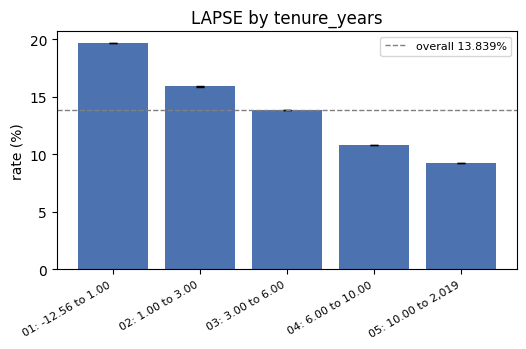

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,01: -12.56 to 1.00,4605121,17.21,905693.0,19.667,19.631,19.703,1.42
lapse,02: 1.00 to 3.00,7335537,27.41,1166024.0,15.896,15.869,15.922,1.15
lapse,03: 3.00 to 6.00,3995619,14.93,553493.0,13.852,13.819,13.886,1.00
lapse,04: 6.00 to 10.00,5067398,18.94,547241.0,10.799,10.772,10.826,0.78
lapse,"05: 10.00 to 2,019",5755150,21.51,530774.0,9.223,9.199,9.246,0.67


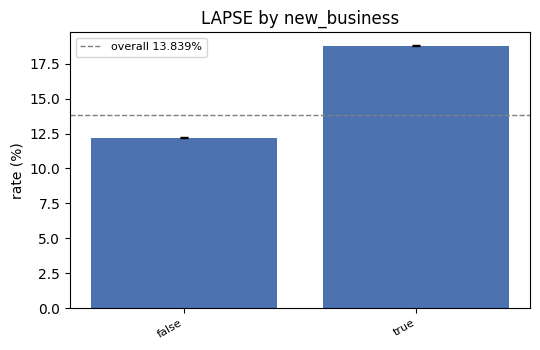

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,false,20104078,75.13,2454376.0,12.208,12.194,12.223,0.88
lapse,true,6654747,24.87,1248849.0,18.766,18.737,18.796,1.36


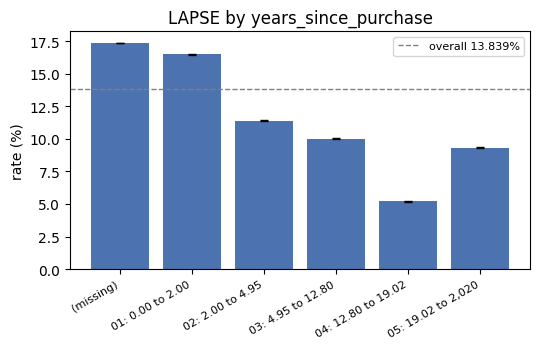

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,(missing),13082623,48.89,2273244.0,17.376,17.356,17.397,1.26
lapse,01: 0.00 to 2.00,2699347,10.09,445287.0,16.496,16.452,16.540,1.19
lapse,02: 2.00 to 4.95,2737428,10.23,311619.0,11.384,11.346,11.421,0.82
lapse,03: 4.95 to 12.80,2726843,10.19,273077.0,10.014,9.979,10.050,0.72
lapse,04: 12.80 to 19.02,2770594,10.35,144168.0,5.204,5.177,5.230,0.38
lapse,"05: 19.02 to 2,020",2741990,10.25,255830.0,9.330,9.296,9.365,0.67


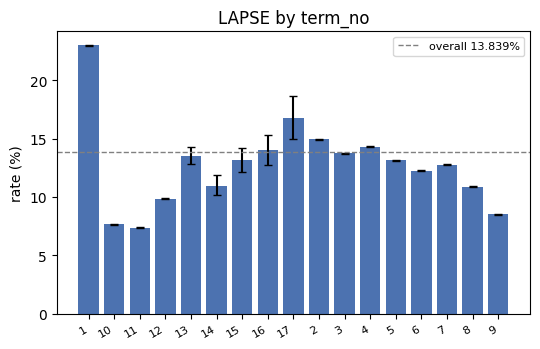

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,1,3915066,14.63,900276.0,22.995,22.954,23.037,1.66
lapse,10,1303940,4.87,99956.0,7.666,7.620,7.711,0.55
lapse,11,912300,3.41,67018.0,7.346,7.293,7.400,0.53
lapse,12,665861,2.49,65627.0,9.856,9.785,9.928,0.71
lapse,13,8395,0.03,1137.0,13.544,12.828,14.292,0.98
lapse,14,5186,0.02,569.0,10.972,10.150,11.852,0.79
lapse,15,4305,0.02,566.0,13.148,12.171,14.190,0.95
lapse,16,2874,0.01,402.0,13.987,12.767,15.304,1.01
lapse,17,1583,0.01,265.0,16.740,14.982,18.660,1.21


,LAPSE,CANCEL_IN_TERM,NON_RENEWAL
tenure_years,,,
01: -12.56 to 1.00,19.667,0.099,19.663
02: 1.00 to 3.00,15.896,0.145,15.891
03: 3.00 to 6.00,13.852,0.161,13.847
04: 6.00 to 10.00,10.799,0.147,10.795
"05: 10.00 to 2,019",9.223,0.128,9.218


In [28]:
# Step 3.5 Tenure
for f, q in [("tenure_years", 5), ("new_business", None), ("years_since_purchase", 5), ("term_no", None)]:
    display(explore(f, keys=("lapse",), q=q))
lapse_parts("tenure_years", q=5)

In [29]:
# Step 3.5b Stability: lapse by new business in each training year
by_year("new_business", "lapse")

group_2,2014,2015,2016,2017,2018,2019,2020
group_1,,,,,,,
false,14.065,16.384,14.326,10.700,9.878,8.806,11.132
true,20.222,22.177,20.782,19.023,17.783,14.509,15.980


Here are your Q5 findings, from the saved outputs of 3.5 and 3.5b. The overall lapse rate in training is **13.84%**.

> **Our findings (Q5):**
> 1. **Lapse falls steadily with tenure.** It drops from **19.67%** in the first year (lift 1.42) to **15.90%** at 1–3 years, **13.85%** at 3–6 years, **10.80%** at 6–10 years and **9.22%** after 10 years (lift 0.67). Policyholders in their first year lapse at more than twice the rate of those with 10+ years.
> 2. **New business lapses about 1.5 times as often, in every year.**
>    - First-year policies (a quarter of policy-years) lapse at **18.77%** (lift 1.36), against **12.21%** for the rest (lift 0.88).
>    - The pattern holds in every training year from 2014 to 2020 (3.5b). The gap ranges from **5.8 points** (2015: 22.18% against 16.38%) to **8.9 points** (2018: 17.78% against 9.88%).
> 3. **The term count tells the same story.**
>    - The first observed term lapses at **23.00%** (lift 1.66), the second at 14.94%, and from the ninth term on the rate is **7.3–8.5%** (lift 0.53–0.62).
>    - Term numbers above 12 are rare (under 0.1% of policy-years) and have wide intervals.
>    - The term count starts from the first term in our data (2009), so it understates the history of older policies; tenure, from the original purchase date of the policy, is the better measure.
> 4. **Recent home buyers lapse more, but the pattern is not smooth.**
>    - Lapse is **16.50%** within 2 years of buying the property (lift 1.19), falling to **5.20%** at 12.8–19 years (lift 0.38), then rising again to **9.33%** after 19 years.
>    - Half of policy-years (49%) have no purchase date, and they lapse at **17.38%** (lift 1.26).
> 5. **Almost all of the tenure effect is non-renewal.** Cancellations during the term stay between **0.10% and 0.16%** in every tenure group.
>
> **Our hypothesis:** supported. Lapse is highest in the first year and after a recent purchase, then falls with tenure, in every training year. Like churn in other industries, the early years are when policyholders decide whether to stay.
>
> **Feature decision:**
> - **`tenure_years`: keep, transform.**
>   - Set impossible values to missing: from **−12.6** (first purchase after the start) to **2,019 years** (a placeholder date).
>   - For logistic regression, use the log of tenure or bins, because the drop is steepest in the first years.
> - **`new_business`: keep** (flag). It is "tenure below 1 year", so it repeats part of tenure, but it marks the biggest step clearly; boosting can use either.
> - **`years_since_purchase`: keep, transform.** Keep "missing" as its own group (49%, with above-average lapse), and set impossible values (up to 2,020 years) to missing. Use bins for logistic regression, because the rate is not monotonic.
> - **`term_no`: keep with low priority, as a number** (not text: 10–17 sort before 2). It overlaps with tenure and is cut off by the start of our data in 2009, so we may drop it after the model comparison.

#### 3.6 Q6. Do past claims predict future claims and change lapse?
**Question:** Is a property with earlier claims more likely to claim again, and does a recent claim make the policyholder keep or drop the cover?

**Our hypothesis:** Earlier claims raise the chance of another claim (repetitive-loss properties). A recent claim lowers lapse (the policyholder has just seen the cover pay out).

**What we look at:** both targets by earlier claims, number of claims and years since the last claim.

**Targets:** both

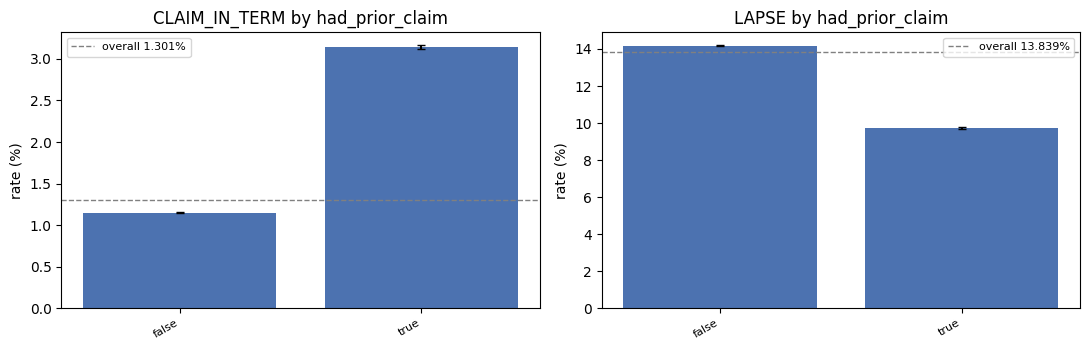

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,false,25420551,92.45,292691.0,1.151,1.147,1.156,0.88
claim,true,2076269,7.55,65131.0,3.137,3.113,3.161,2.41
lapse,false,24734372,92.43,3506010.0,14.175,14.161,14.188,1.02
lapse,true,2024453,7.57,197215.0,9.742,9.701,9.783,0.70


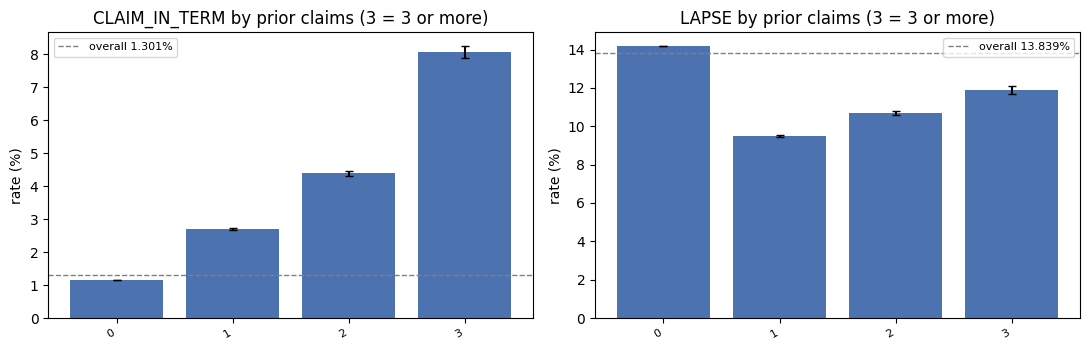

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,0,25420551,92.45,292691.0,1.151,1.147,1.156,0.88
claim,1,1728899,6.29,46759.0,2.705,2.680,2.729,2.08
claim,2,262835,0.96,11552.0,4.395,4.317,4.474,3.38
claim,3,84535,0.31,6820.0,8.068,7.886,8.253,6.20
lapse,0,24734372,92.43,3506010.0,14.175,14.161,14.188,1.02
lapse,1,1686254,6.30,160082.0,9.493,9.449,9.538,0.69
lapse,2,255938,0.96,27352.0,10.687,10.568,10.807,0.77
lapse,3,82261,0.31,9781.0,11.890,11.671,12.113,0.86


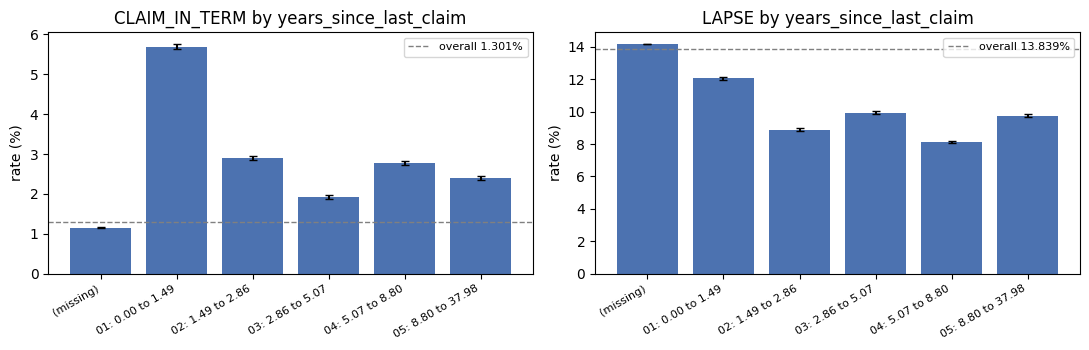

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,(missing),25420551,92.45,292691.0,1.151,1.147,1.156,0.88
claim,01: 0.00 to 1.49,415478,1.51,23662.0,5.695,5.625,5.766,4.38
claim,02: 1.49 to 2.86,415160,1.51,12000.0,2.890,2.840,2.942,2.22
claim,03: 2.86 to 5.07,414895,1.51,7976.0,1.922,1.881,1.965,1.48
claim,04: 5.07 to 8.80,415576,1.51,11554.0,2.780,2.731,2.831,2.14
claim,05: 8.80 to 37.98,415160,1.51,9939.0,2.394,2.348,2.441,1.84
lapse,(missing),24734372,92.43,3506010.0,14.175,14.161,14.188,1.02
lapse,01: 0.00 to 1.49,401540,1.50,48417.0,12.058,11.957,12.159,0.87
lapse,02: 1.49 to 2.86,403954,1.51,35864.0,8.878,8.791,8.966,0.64


In [30]:
# Step 3.6 Prior claims
display(explore("had_prior_claim"))
display(explore("LEAST(prior_claims_n, 3)", label="prior claims (3 = 3 or more)"))
explore("years_since_last_claim", q=5)

Here are your Q6 findings, from the saved outputs of Step 3.6. Overall in training, the claim rate is about **1.30%** and the lapse rate **13.84%**.

> **Our findings (Q6):**
> 1. **A property with earlier claims is much more likely to claim again, and the risk grows with every claim.**
>    - Properties with at least one earlier claim (7.6% of policy-years) claim at **3.14%** (lift 2.41), against **1.15%** for those without: **2.7 times higher**.
>    - By number of earlier claims, the rate rises from 1.15% (none) to **2.71%** (one), **4.40%** (two) and **8.07%** for three or more (lift 6.20), **7 times** the rate of properties with no claim.
>    - This is the repetitive-loss pattern: the same properties flood again and again.
> 2. **The risk is highest right after a claim.**
>    - A claim within the last **1.5 years** gives a claim rate of **5.70%** (lift 4.38).
>    - After that the rate drops to about **1.9–2.9%**, but it stays above the no-claim rate (1.15%) even when the last claim was 9 to 38 years ago.
>    - The pattern after the first year is not smooth (2.89%, 1.92%, 2.78%, 2.39%), which likely reflects which storm years fall in each group.
> 3. **Policyholders with earlier claims keep their cover more often.**
>    - They lapse at **9.74%** (lift 0.70), against **14.18%** for those without a claim: **31% lower**.
>    - Having seen the policy pay out, they value it more. A mortgage requirement after a loss, or the knowledge that the property floods, may add to this.
> 4. **But the effect weakens with more claims and right after a claim.**
>    - Lapse rises from **9.49%** with one earlier claim to **11.89%** with three or more, still below the no-claim rate.
>    - Among policyholders with a claim, lapse is highest when the claim was **within 1.5 years (12.06%)**, against 8.1–9.9% when it was longer ago.
>    - So the opposite of our hypothesis holds right after a claim. Some properties are probably sold, rebuilt or left empty after major damage, which ends the policy.
>
> **Our hypothesis:** the claim part is strongly supported: earlier claims are one of the strongest signals for future claims we have found so far (lift up to 6.2). The lapse part is only partly supported: earlier claims lower lapse overall, but less so right after a claim and for properties with many claims. We did not check these patterns by year.
>
> **Feature decision:**
> - **`prior_claims_n`: keep, transform.** Cap it at 3 ("3 or more"), because the groups above 3 are small; for logistic regression use the capped count as categories or a log.
> - **`had_prior_claim`: keep** (flag). It is "count above 0", so it repeats the count, but it separates the 92% with no claim cleanly, and `years_since_last_claim` needs it.
> - **`years_since_last_claim`: keep, transform.** It is missing whenever there was no earlier claim (92%). For logistic regression we fill the missing values with a fixed value and let `had_prior_claim` carry the "no claim" effect, and use bins (within 1.5 years / 1.5–5 / 5+), because the effect is not linear.
> - **`prior_claims_paid`** (not shown here): use with care. Amounts of earlier claims can be settled after the start, so the total may include payments that were not yet known. The count and the dates are safe; the amount should be checked before use.

#### 3.7 Q7. How are claims and cancellations related?
**Question:** Do policyholders cancel in the same policy-year as a claim, or in the year after one?

**Our hypothesis:** Cancellation is lower in the year of a claim and the year after, because the policyholder needs the cover to be paid and to rebuild.

**What we look at:** cancel rate by claim in the same policy-year (two outcomes, so this is description, not a feature), and by a claim in the 12 months before the start (a feature).

**Targets:** `CANCEL_IN_TERM` (the mid-term part of `LAPSE`) and `LAPSE`

In [31]:
# Step 3.7a Same policy-year: claim and cancellation (descriptive only: both are outcomes)
display(rate_table(con, "features", "claim_count > 0", "CANCEL_IN_TERM",
                   where=f"{TRAIN} AND in_pop_lapse", min_n=MIN_N))

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
0,false,26408254,98.69,36293.0,0.137,0.136,0.139,1.01
1,true,350571,1.31,161.0,0.046,0.039,0.054,0.34


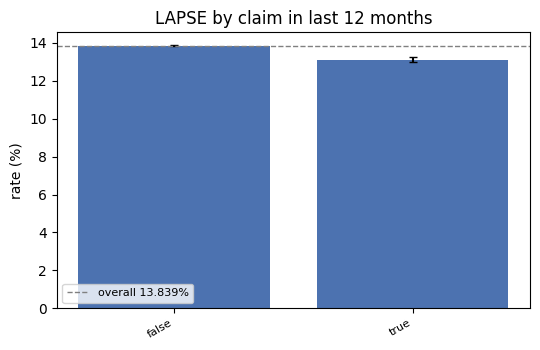

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,false,26481295,98.96,3666845.0,13.847,13.834,13.860,1.00
lapse,true,277530,1.04,36380.0,13.108,12.983,13.235,0.95


In [32]:
# Step 3.7b Claim in the 12 months before the start (a feature), against lapse
explore("COALESCE(years_since_last_claim < 1, FALSE)", keys=("lapse",), label="claim in last 12 months")

Here are your Q7 findings, from the saved outputs of 3.7a and 3.7b. In training, cancellation during the term is rare: **0.14%** of lapse-population policy-years. The overall lapse rate is **13.84%**.

> **Our findings (Q7):**
> 1. **Policyholders almost never cancel in the same policy-year as a claim.** Policy-years with a claim cancel during the term at **0.046%** (161 of 350,571), against **0.137%** without a claim (lift 0.34): **3 times lower**. Someone whose claim is being paid, or who is rebuilding, keeps the cover until the end of the term. This is a description only: the claim and the cancellation are both outcomes of the same year, so neither can predict the other.
> 2. **A claim in the 12 months before the start barely changes lapse.** Policyholders with a claim in the previous 12 months (1.0% of policy-years) lapse at **13.11%** (lift 0.95), against **13.85%** for the rest: only **5% lower**. Most lapse is non-renewal at the end of the term, so the cover needed during the claim year does not carry into the next year.
> 3. **This matches Q6: the lower lapse after a claim comes from older claims, not recent ones.** Policyholders whose last claim was more than 1.5 years ago lapse at about **8–10%**, while those with a recent claim are close to the average.
>
> **Our hypothesis:** partly supported. Cancellation is clearly lower **in the year of a claim** (3 times lower), but **not in the year after** (5% lower). The link between claims and lapse is strongest during the claim year itself, which the model cannot use, because the claim isn't known at the start.
>
> **Feature decision:**
> - **A claim in the same policy-year (`claim_count`, `CLAIM_IN_TERM`): not a feature.** It is an outcome of the year we predict, so using it would leak; it stays in `TARGET_ONLY`.
> - **A "claim in the last 12 months" flag: don't add.** It is weak for lapse (lift 0.95) and already covered by `years_since_last_claim`, whose "within 1.5 years" bin carries the same information (Q6).
> - We keep the **claim and lapse models separate**: a predicted claim probability is not used as an input to the lapse model, because the strongest link is within the same year, which isn't known at the start.

#### 3.8 Q8. Does the neighborhood and economic context matter?
**Question:** Do recent flood disasters, tract income and home values, interest rates and the community's CRS class relate to claims or lapse?

**Our hypothesis:** A recent flood disaster raises awareness, so lapse falls and coverage is kept. Lower-income tracts lapse more. Higher mortgage rates change lapse through refinancing and home sales. Better CRS classes have fewer claims.

**What we look at:** both targets by flood disasters in the last 12 months, tract income, mortgage rate and CRS class.

**Targets:** both

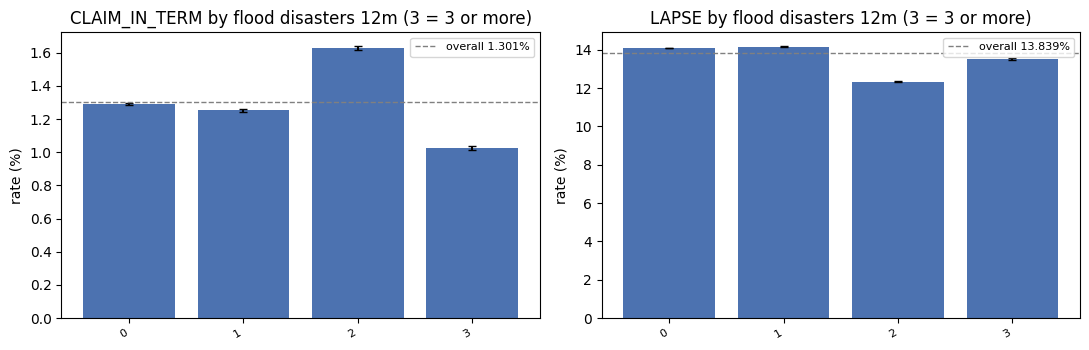

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,0,16481982,59.94,212758.0,1.291,1.285,1.296,0.99
claim,1,5094153,18.53,63838.0,1.253,1.244,1.263,0.96
claim,2,3402042,12.37,55365.0,1.627,1.614,1.641,1.25
claim,3,2518643,9.16,25861.0,1.027,1.014,1.039,0.79
lapse,0,16065563,60.04,2263297.0,14.088,14.071,14.105,1.02
lapse,1,4960909,18.54,703128.0,14.173,14.143,14.204,1.02
lapse,2,3289826,12.29,406201.0,12.347,12.312,12.383,0.89
lapse,3,2442527,9.13,330599.0,13.535,13.492,13.578,0.98


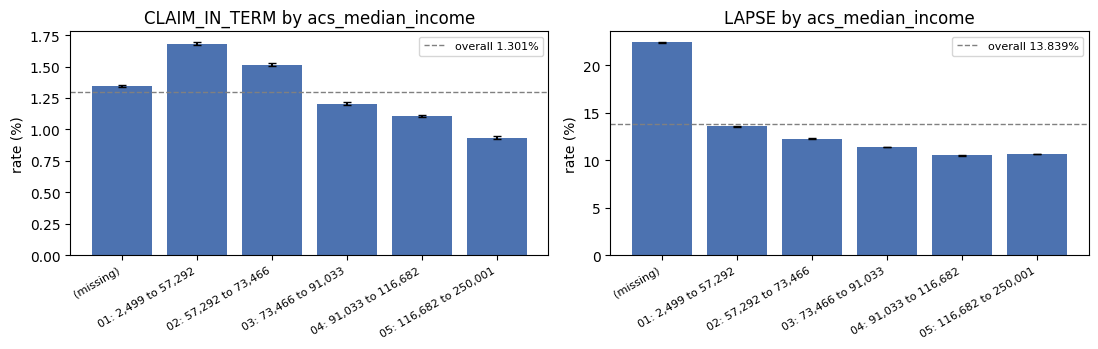

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,(missing),5638895,20.51,75992.0,1.348,1.338,1.357,1.04
claim,"01: 2,499 to 57,292",4370383,15.89,73562.0,1.683,1.671,1.695,1.29
claim,"02: 57,292 to 73,466",4371142,15.90,66143.0,1.513,1.502,1.525,1.16
claim,"03: 73,466 to 91,033",4363827,15.87,52630.0,1.206,1.196,1.216,0.93
claim,"04: 91,033 to 116,682",4380988,15.93,48565.0,1.109,1.099,1.118,0.85
claim,"05: 116,682 to 250,001",4371585,15.90,40930.0,0.936,0.927,0.945,0.72
lapse,(missing),5387003,20.13,1206835.0,22.403,22.368,22.438,1.62
lapse,"01: 2,499 to 57,292",4289002,16.03,581435.0,13.556,13.524,13.589,0.98
lapse,"02: 57,292 to 73,466",4272316,15.97,524914.0,12.286,12.255,12.318,0.89


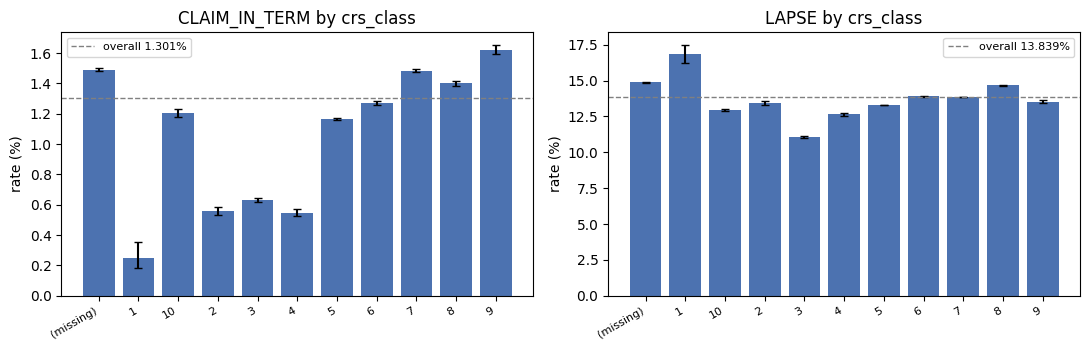

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
claim,(missing),7280090,26.48,108462.0,1.490,1.481,1.499,1.14
claim,1,13505,0.05,34.0,0.252,0.180,0.352,0.19
claim,10,685079,2.49,8259.0,1.206,1.180,1.232,0.93
claim,2,334800,1.22,1864.0,0.557,0.532,0.583,0.43
claim,3,1448390,5.27,9136.0,0.631,0.618,0.644,0.48
claim,4,390398,1.42,2144.0,0.549,0.526,0.573,0.42
claim,5,7053365,25.65,82207.0,1.166,1.158,1.173,0.90
claim,6,3059157,11.13,38918.0,1.272,1.260,1.285,0.98
claim,7,4941130,17.97,73334.0,1.484,1.474,1.495,1.14


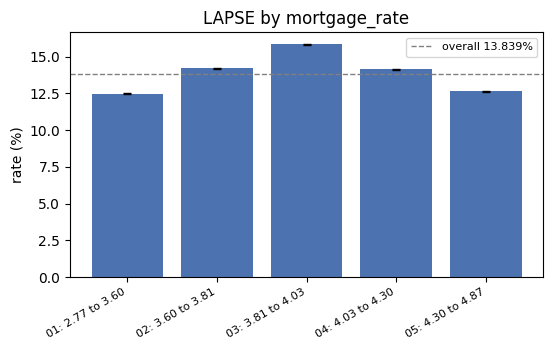

,group,n,share_pct,positives,rate_pct,ci_low_pct,ci_high_pct,lift
population,,,,,,,,
lapse,01: 2.77 to 3.60,5081107,18.99,633144.0,12.461,12.432,12.489,0.90
lapse,02: 3.60 to 3.81,5873721,21.95,833342.0,14.188,14.159,14.216,1.03
lapse,03: 3.81 to 4.03,5012834,18.73,793137.0,15.822,15.790,15.854,1.14
lapse,04: 4.03 to 4.30,5239365,19.58,741315.0,14.149,14.119,14.179,1.02
lapse,05: 4.30 to 4.87,5551798,20.75,702287.0,12.650,12.622,12.677,0.91


In [33]:
# Step 3.8 Context
display(explore("LEAST(flood_disasters_12m, 3)", label="flood disasters 12m (3 = 3 or more)"))
display(explore("acs_median_income", q=5))
display(explore("crs_class"))
explore("mortgage_rate", keys=("lapse",), q=5)

> **Careful with FRED features:** mortgage rates, unemployment and inflation are the same for every policy in a month, so they move with the year. A pattern by mortgage rate can be a pattern by year (for example the Risk Rating 2.0 period, when rates also rose). We read them together with `by_year()` before keeping them.

Here are your Q8 findings, from the saved outputs of Step 3.8. Overall in training, the claim rate is about **1.30%** and the lapse rate **13.84%**.

> **Our findings (Q8):**
> 1. **Tract income is related to both targets: poorer tracts claim more and lapse more.**
>    - The claim rate falls steadily from **1.68%** in the lowest-income fifth (median income up to $57,292, lift 1.29) to **0.94%** in the highest (above $116,682, lift 0.72): **1.8 times higher** in the poorest tracts.
>    - Lapse falls from **13.56%** to about **10.5–10.7%** (lift 0.76–0.77): **27% higher** in the poorest tracts.
>    - Lower-income neighborhoods are often in lower-lying, older housing areas, and their policyholders are more sensitive to price.
> 2. **Policy-years without ACS data lapse far more: 22.40% (lift 1.62, 20% of policy-years).** Their claim rate is close to average (1.35%). A gap this large in lapse but not in claims is not an income effect. It suggests the tract code is missing or out of date more often on policies that lapse, which we need to check before using it.
> 3. **Communities with the best CRS classes have about half the claims.**
>    - Policy-years in CRS **classes 1–4** claim at **0.25–0.63%** (lift 0.19–0.48).
>    - From class 5 to class 9, the rate rises from **1.17%** to **1.62%** (lift 0.90 to 1.25).
>    - Communities that do more floodplain management (better class) have fewer claims, though the best classes are few communities (classes 1–4 are 8% of policy-years), so part of the effect may be those particular places.
>    - CRS class barely affects lapse (11.1–14.9%, except class 1 with only 13,228 policy-years).
> 4. **Recent flood disasters show no clear pattern.**
>    - The claim rate is 1.25–1.29% with zero or one declaration in the past 12 months, **1.63%** with two (lift 1.25), and **1.03%** with three or more (lift 0.79).
>    - Lapse moves little, from 12.35% to 14.17%.
>    - Declarations cover whole counties or states, so they are a coarse measure of what happened at the property.
> 5. **Mortgage rate patterns follow the year, not the rate.** Lapse is lowest at both ends of the rate range (**12.46%** below 3.60% and **12.65%** above 4.30%) and highest in the middle (**15.82%** at 3.81–4.03%). The mortgage rate is the same for every policy in a month, so this mostly reflects which years fall in each group, as we noted above.
>
> **Our hypothesis:**
> - **Supported:** lower-income tracts lapse more (and claim more), and better CRS classes have fewer claims (about half for classes 1–4).
> - **Not supported:** recent disasters lowering lapse.
> - **Can't separate from the year:** the effect of mortgage rates.
> - We did not check these patterns by year.
>
> **Feature decision:**
> - **`acs_median_income` (and the other ACS features): keep.** Hold back a "missing ACS" flag until we check why missing values lapse so much more, for example by `period_year` and by the tract-code vintage (2010 or 2020 tracts). If missingness depends on the outcome, we use income without the flag and impute the missing values.
> - **`crs_class`: keep** as a category. Merge classes 1–4 into one group, because each is small; keep "missing" (26%, no CRS record) as its own group.
> - **`flood_disasters_12m`: keep with low priority**, capped at 3. The effect is weak and not monotonic, and we may drop it after the model comparison.
> - **`mortgage_rate` and the other FRED features: drop.** They work as a proxy for the year. Their training range (2.8–4.9%) also doesn't cover the test and validation years (about 5–7% in 2022–2024), so the model would be scoring rates it never saw.

### Section 4. Feature screening
We put every feature on one scale: its **univariate AUC**, the chance that a random positive policy-year scores higher than a random negative one using that feature alone. 0.5 means no signal. We report `strength = max(AUC, 1 − AUC)`, so a feature that works in the other direction also counts. We use the sampled training rows (`sample_<population>`), which gives the same AUC as the full data.

This takes a few minutes: there are about 70 features and 3 targets.

In [34]:
# Step 4.1 Univariate AUC of every feature for every target (training split)
kinds = {f[0]: f[2] for f in FEATURES}
rows = []
for key, target in TARGETS.items():
    for name in feature_names():
        n, pos, auc = con.execute(univariate_auc_sql("features", name, target,
                                                     where=f"{TRAIN} AND sample_{key}", kind=kinds[name])).fetchall()[0]
        rows.append({"feature": name, "population": key, "rows_used": n, "auc": auc})
screening = pd.DataFrame(rows)
screening["strength"] = screening["auc"].map(lambda a: max(a, 1 - a) if pd.notna(a) else None).round(3)
strength = screening.pivot(index="feature", columns="population", values="strength")
strength = meta.set_index("feature")[["group", "kind"]].join(strength).sort_values("claim", ascending=False)
strength

,group,kind,claim,lapse
feature,,,,
heavy_rain_days_3y,context,num,0.617,0.522
premium_per_1k_coverage,price,num,0.609,0.532
acs_median_home_value,context,num,0.605,0.527
precip_max1d_mean_mm,context,num,0.601,0.519
years_since_last_claim,history,num,0.589,0.529
...,...,...,...,...
rr2_rated,price,flag,0.500,0.500
multi_year_term,tenure,flag,0.500,0.500
new_business,tenure,flag,0.500,0.551


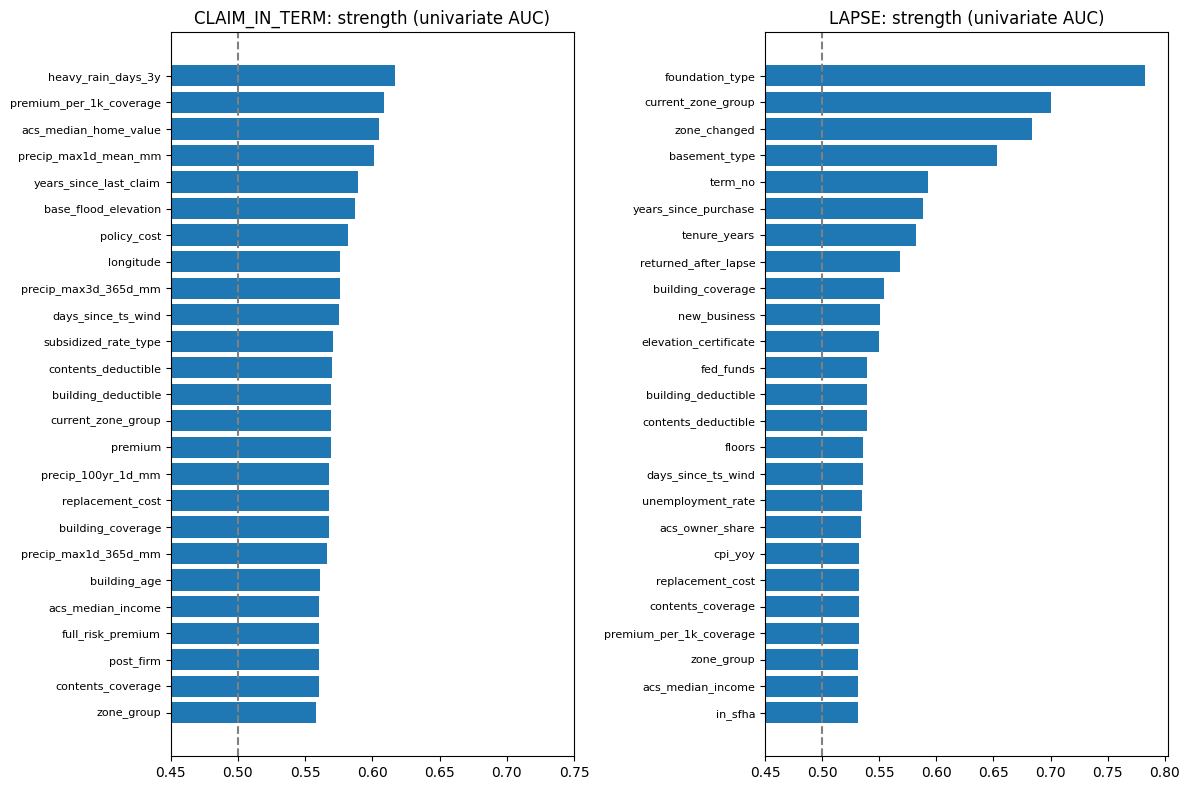

In [35]:
# Step 4.2 Chart: the 25 strongest features for each target
fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 8))
for ax, key in zip(axes, TARGETS):
    top = strength[key].dropna().sort_values().tail(25)
    ax.barh(top.index, top.values)
    ax.axvline(0.5, color="grey", linestyle="--")
    ax.set(title=f"{TARGETS[key]}: strength (univariate AUC)", xlim=(0.45, max(0.75, top.max() + 0.02)))
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.savefig(REPORTS / "fig_feature_screening.png", dpi=150)
plt.show()

> **Our findings:**
> - **Claims:** the strongest single features are recent heavy rain (`heavy_rain_days_3y`, 0.617), the price per $1,000 of cover (0.609), tract home value (0.605), the place's typical wettest day (`precip_max1d_mean_mm`, 0.601) and the time since the last claim (0.589). Rainfall and location features rank above most policy fields. No feature is strong on its own (all below 0.62), so the model has to combine them.
> - **Lapse:** the top four (`foundation_type` 0.783, `current_zone_group` 0.700, `zone_changed` 0.684, `basement_type` 0.653) are building and rating fields whose missing values appear to depend on lapse (Section 5), so we hold them back. After them, tenure features lead (`term_no` 0.593, `years_since_purchase` 0.588, `tenure_years` 0.582), as we found in Q5.
> - Thirteen features show no signal for either target (strength 0.51 or less), including `rr2_rated`, `year_in_term`, `multi_year_term`, `community_emergency_program` and `flood_disasters_12m`.
> - For numbers, the screening skips missing rows, so it can miss a signal that is carried by missing values (as for `discount_to_full_risk`). Step 5.2d checks this directly.

### Section 5. Leakage audit
A feature **leaks** when it contains information from after the start of the policy-year. The model then looks excellent in testing and fails in use.

#### 5.1 When is every feature known?
We record for every feature why it is available at the start of the policy-year (`known_at` in `FEATURES`).

In [36]:
# Step 5.1 The known-at table
meta[["feature", "group", "source", "known_at"]]

,feature,group,source,known_at
0,premium,price,policies,set when the term is rated
1,policy_cost,price,policies,set when the term is rated
2,premium_per_1k_coverage,price,policies,set when the term is rated
3,rr2_rated,price,policies,set when the term is rated
4,full_risk_premium,price,policies,set when the term is rated
...,...,...,...,...
81,home_price_yoy,context,FRED,published 2 months later
82,fed_funds,context,FRED,published monthly
83,community_emergency_program,context,community status book,current snapshot (see leakage audit)
84,community_sanctioned_before,context,community status book,sanction date before the start


#### 5.2 Automatic checks
Each check should print 0, or `ok`.

In [37]:
# Step 5.2a No outcome column is in the feature list
overlap = set(feature_names()) & TARGET_ONLY
print("outcome columns used as features:", overlap or "none")

# Step 5.2b Prior claims, disasters, storms and rain only use dates before the start
display(con.sql('''
    SELECT COUNT(*) FILTER (WHERE last_prior_loss_date >= period_start)  AS claims_on_or_after_start,
           COUNT(*) FILTER (WHERE last_declaration_date >= period_start) AS declarations_on_or_after_start,
           COUNT(*) FILTER (WHERE last_wind_date >= period_start)        AS storms_on_or_after_start,
           COUNT(*) FILTER (WHERE precip_last_day >= period_start)       AS rain_on_or_after_start,
           COUNT(*) FILTER (WHERE years_since_map IS NULL AND community_id6 IS NOT NULL) AS map_dated_after_start_or_missing
    FROM features
''').df())

outcome columns used as features: none


,claims_on_or_after_start,declarations_on_or_after_start,storms_on_or_after_start,rain_on_or_after_start,map_dated_after_start_or_missing
0,0,0,0,0,20692492


In [38]:
# Step 5.2c Features that are suspiciously strong on their own (strength above 0.85)
suspicious = screening[screening["strength"] > 0.85]
suspicious if len(suspicious) else print("no feature has strength above 0.85")

no feature has strength above 0.85


In [39]:
# Step 5.2d Missing values that depend on the outcome: rate when a feature is missing vs filled
# (a date check can't catch a field that is only filled in for policies that stayed)
miss_cols = feature_profile.loc[feature_profile["missing_pct"] > 1, "feature"].tolist()

def by_missing(target, pop):
    exprs = ",\n".join(
        f'AVG(CASE WHEN {f} IS NULL THEN CAST({target} AS DOUBLE) END) AS "{f}|missing", '
        f'AVG(CASE WHEN {f} IS NOT NULL THEN CAST({target} AS DOUBLE) END) AS "{f}|filled"' for f in miss_cols)
    s = con.sql(f"SELECT {exprs} FROM features WHERE {TRAIN} AND in_pop_{pop}").df().iloc[0]
    out = pd.DataFrame({"feature": miss_cols,
                        f"{pop}_missing_pct": [100 * s[f"{f}|missing"] for f in miss_cols],
                        f"{pop}_filled_pct": [100 * s[f"{f}|filled"] for f in miss_cols]})
    out[f"{pop}_ratio"] = out[f"{pop}_missing_pct"] / out[f"{pop}_filled_pct"]
    return out

miss_check = by_missing("LAPSE", "lapse").merge(by_missing("CLAIM_IN_TERM", "claim"), on="feature").round(3)
# Suspicious: being missing changes lapse a lot (ratio above 2 or below 0.5), or changes lapse clearly
# (above 1.5 or below 0.67) while claims stay about the same (0.8 to 1.25)
miss_check["suspicious"] = (~miss_check["lapse_ratio"].between(0.5, 2)) | (
    (~miss_check["lapse_ratio"].between(0.67, 1.5)) & miss_check["claim_ratio"].between(0.8, 1.25))

# The same idea for tenure: a first purchase dated after the start
display(con.sql(f'''
    SELECT tenure_years < 0 AS first_purchase_after_start, COUNT(*) AS policy_years,
           ROUND(100 * AVG(CAST(LAPSE AS DOUBLE)), 2) AS lapse_pct
    FROM features WHERE {TRAIN} AND in_pop_lapse GROUP BY 1 ORDER BY 1
''').df())
miss_check.sort_values("lapse_ratio", ascending=False)

,first_purchase_after_start,policy_years,lapse_pct
0,False,25634625,14.37
1,True,1124200,1.72


,feature,lapse_missing_pct,lapse_filled_pct,lapse_ratio,claim_missing_pct,claim_filled_pct,claim_ratio,suspicious
0,full_risk_premium,27.579,0.604,45.650,1.368,1.233,1.110,True
1,discount_to_full_risk,27.579,0.604,45.650,1.368,1.233,1.110,True
9,foundation_type,27.579,0.604,45.650,1.368,1.233,1.110,True
5,current_zone_group,55.662,9.035,6.160,0.930,1.347,0.691,True
6,zone_changed,55.662,9.035,6.160,0.930,1.347,0.691,True
10,basement_type,19.857,7.552,2.629,1.333,1.268,1.051,True
27,acs_population,22.520,11.674,1.929,1.345,1.290,1.043,True
26,acs_owner_share,22.509,11.673,1.928,1.345,1.290,1.042,True
25,acs_median_age,22.512,11.673,1.928,1.345,1.290,1.043,True
23,acs_median_income,22.403,11.681,1.918,1.348,1.289,1.045,True


#### 5.3 Known limits we accept
These features are known at the start in practice, but we record their limits:

| Feature | Limit | What we do |
|---|---|---|
| `acs_*` | The 2018–2022 averages overlap our 2018–2020 training years and come after 2014–2017. Missing values lapse at 22.5% against 11.7% (5.2d). | Keep the values: tract income and home values move slowly. Impute without a missing flag. |
| `prior_claims_paid` | Amounts on recent earlier claims may have been settled after the start. | Keep with care: the count and recency are exact; only the amount can be slightly ahead. |
| `crs_class` | Taken from the status book, a current snapshot: the class may have changed since the policy-year. | Keep: classes change slowly; we note that it describes the community today. |
| `tenure_years` | 4.1% of training policy-years have a first purchase dated more than a year after the start; they lapse at 1.7% against 14.4%. The date was updated later. | Keep, but these values become missing and are filled with the training median **without** a missing flag; `new_business` is recomputed from the cleaned tenure (`apply_fixed_rules`). |
| `community_emergency_program` | Current snapshot, with no date. | Drop: no signal (strength 0.50) and the snapshot problem. |
| `years_since_map` | Only the current map date exists; for 51% of policy-years the current map came after the start, so the value is blanked. | Drop: mostly empty, and whether it is empty depends on later map revisions. |
| Static rainfall (1981–2013) and 10-year wind history | Describe the place before our first start. | Keep: known at every start date. |

> **Our conclusion:**
>
> **1. Every automatic check passed.** No outcome column is used as a feature (5.2a). Every dated feature uses only information from before the start: **0** earlier claims, **0** disaster declarations, **0** storms and **0** rain on or after the start date (5.2b). No feature is suspiciously strong on its own: the strongest is `foundation_type` for lapse, at **0.783**, below our 0.85 threshold (5.2c).
>
> **2. But the checks only look at dates, and the screening shows a second kind of leakage: missing values that depend on the outcome.**
> - The four strongest lapse features are building and rating fields: `foundation_type` (0.783), `current_zone_group` (0.700), `zone_changed` (0.684) and `basement_type` (0.653). Real lapse drivers such as tenure only reach 0.58.
> - `foundation_type` is missing for exactly the same 50.43% of training rows as `full_risk_premium` and `discount_to_full_risk`, where a missing value meant a **27.6%** lapse rate and a filled one **0.55–0.63%** (Q3). These fields seem to have been recorded mainly for policies that stayed, so "missing" tells the model the policy lapsed.
> - The same holds for tenure: 4.1% of training policy-years have a first purchase dated after the start, and they lapse at **1.7%** against **14.4%**.
> - **Step 5.2d confirms it.** When `full_risk_premium`, `discount_to_full_risk` or `foundation_type` is missing, the lapse rate is **27.6%**; when filled, **0.6%** (46 times). For `current_zone_group` and `zone_changed` it is **55.7%** against **9.0%** (6 times), and for `basement_type` **19.9%** against **7.6%**. The claim rate barely changes for the first group (1.37% against 1.23%), so this is about how the records were kept, not about risk. **We drop these six fields.**
> - 5.2d also flags patterns we can explain. The first-term features (`premium_change_pct`, `prev_gap_days`, `returned_after_lapse`) are missing for new business, which really does lapse more (Q5). The ACS features (22.5% against 11.7%) and `years_since_purchase` (17.4% against 10.5%) are less clear, so we use their values **without** a missing flag (6.1).
>
> **3. The community status book is a current snapshot.** For **20,692,492** policy-years (51%) the community's current map is dated after the start, so `years_since_map` is blanked. We drop it and `community_emergency_program`, and keep `crs_class` with the snapshot noted as a limit.
>
> **4. Features we drop for other reasons:** `rr2_rated` is constant in training (Q3), and the FRED features are a proxy for the year whose test and validation values fall outside the training range (Q8).
>
> **5. In short:** after these removals, every feature we keep is known at the start of the policy-year and doesn't reveal the outcome through being missing. The fields dropped for outcome-dependent missingness could return only if their records were completed independently of the outcome.

### Section 6. Missing values and encoding plan
We decide **how** each feature is prepared here; notebooks 06 and 07 apply the plan inside the model pipeline, fitted on the training split only (medians, category lists), and then transform validation and test with the same values.

#### 6.1 Missing values
Our rules:

| Kind | Rule | Exceptions where NULL has a meaning |
|---|---|---|
| Number | median of the training split, plus a `<feature>_missing` flag | `years_since_last_claim`: NULL = no earlier claim → 99. `premium_change_pct`, `coverage_change_pct`, `prev_gap_days`: NULL = first term → 0 and the flag. `tenure_years`, `years_since_purchase` and the ACS features → median **without** a flag, because their missingness is tied to lapse and the flag would leak (Section 5). |
| Category | NULL becomes its own category, `(missing)` | none: `crs_class` keeps `(missing)` apart from class 10, because missing policy-years claim more (1.49% against 1.21%, Q8) |
| Flag | true / false / `(missing)` as three categories when anything is missing | none |

Before these rules, `src.features.apply_fixed_rules` applies the fixed clean-up rules (impossible values → missing, caps that learn nothing from the data, merged categories); see "Our decisions" below.

In [40]:
# Step 6.1 Missing-value plan per feature
SPECIAL_MISSING = {
    "years_since_last_claim": "fill 99 (no earlier claim)",
    "premium_change_pct": "fill 0 + missing flag (first term)",
    "coverage_change_pct": "fill 0 + missing flag (first term)",
    "prev_gap_days": "fill 0 + missing flag (first term)",
    "crs_class": "'(missing)' category (not the same as class 10)",
    "tenure_years": "median (train), NO missing flag (impossible values leak, Section 5)",
    "years_since_purchase": "median (train), NO missing flag (missingness tied to lapse, 5.2d)",
    **{f: "median (train), NO missing flag (missingness tied to lapse, 5.2d)"
       for f in ["acs_median_income", "acs_median_home_value", "acs_median_age", "acs_owner_share", "acs_population"]},
}

def missing_plan(r):
    if r["feature"] in SPECIAL_MISSING:
        return SPECIAL_MISSING[r["feature"]]
    if r["missing_pct"] == 0:
        return "none"
    return {"num": "median (train) + missing flag", "cat": "'(missing)' category",
            "flag": "true / false / '(missing)'"}[r["kind"]]

plan = feature_profile.copy()
plan["missing_plan"] = plan.apply(missing_plan, axis=1)
plan[plan["missing_pct"] > 0].sort_values("missing_pct", ascending=False)

,feature,group,kind,missing_pct,distinct,min,max,missing_plan
54,years_since_last_claim,history,num,92.45,10822,0.0027378507871321013,37.98494182067078,fill 99 (no earlier claim)
22,obstruction_type,flood_risk,cat,81.00,20,10,98,'(missing)' category
21,elevation_certificate,flood_risk,cat,78.22,9,1,E,'(missing)' category
16,base_flood_elevation,flood_risk,num,66.68,32148,-9999.00,9994.00,median (train) + missing flag
15,elevation_difference,flood_risk,num,66.48,712,-90000,998,median (train) + missing flag
85,years_since_map,context,num,63.51,15238,0.0,70.79808350444901,median (train) + missing flag
19,basement_type,flood_risk,cat,51.73,4,0,4,'(missing)' category
18,foundation_type,flood_risk,cat,50.43,6,1,6,'(missing)' category
5,discount_to_full_risk,price,num,50.43,36280,-137941,31552,median (train) + missing flag
4,full_risk_premium,price,num,50.43,16938,59,38819,median (train) + missing flag


#### 6.2 Encoding
Coded columns (occupancy, zones, deductibles, rate types) are categories, not numbers: occupancy code 4 is not "twice" code 2.

We use `occupancy_group`, not the raw `occupancyType`. Risk Rating 2.0 replaced codes 1–6 with codes 11–19 (notebook 03, Step 6.2b), so the raw code would tell the model whether a term was rated after 2021, and old code 1 covers what is now 11, 14 and 16. The four groups mean the same thing before and after the change.

| Kind | Logistic regression (06) | Gradient boosting (07) |
|---|---|---|
| Number | standardize (subtract mean, divide by standard deviation) | as is |
| Category, 15 levels or fewer | one-hot | one-hot or native categorical |
| Category, more than 15 levels | keep the 15 most frequent levels in train, group the rest as `other`, then one-hot | same |
| Flag | 0 / 1 (plus the missing category if any) | same |

We use one-hot encoding and not target encoding, because target encoding needs careful cross-fitting to avoid leaking the target, and our categories have few levels.

In [41]:
# Step 6.2 Encoding plan per feature
def encoding(r):
    if r["kind"] == "num":
        return "standardize (logistic) / as is (boosting)"
    if r["kind"] == "flag":
        return "0/1"
    return "one-hot" if r["distinct"] <= 15 else "top 15 levels + 'other', one-hot"

plan["encoding"] = plan.apply(encoding, axis=1)
plan = plan.merge(strength[list(TARGETS)].add_prefix("strength_"), left_on="feature", right_index=True, how="left")
plan[["feature", "group", "kind", "distinct", "missing_pct", "missing_plan", "encoding"]]

,feature,group,kind,distinct,missing_pct,missing_plan,encoding
0,premium,price,num,23148,0.00,none,standardize (logistic) / as is (boosting)
1,policy_cost,price,num,24548,0.00,none,standardize (logistic) / as is (boosting)
2,premium_per_1k_coverage,price,num,2075300,0.00,none,standardize (logistic) / as is (boosting)
3,rr2_rated,price,flag,1,0.00,none,0/1
4,full_risk_premium,price,num,16938,50.43,median (train) + missing flag,standardize (logistic) / as is (boosting)
...,...,...,...,...,...,...,...
81,home_price_yoy,context,num,85,0.00,none,standardize (logistic) / as is (boosting)
82,fed_funds,context,num,48,0.00,none,standardize (logistic) / as is (boosting)
83,community_emergency_program,context,flag,2,0.00,none,0/1
84,community_sanctioned_before,context,flag,2,0.00,none,0/1


> **Our decisions:**
> - **We drop 18 features** (reasons in `DROP_FEATURES`, Step 6.3):
>   - **Leakage (6):** `full_risk_premium`, `discount_to_full_risk`, `foundation_type`, `basement_type`, `current_zone_group`, `zone_changed`. Whether they are filled depends on lapse: missing values lapse 2.6 to 46 times as often (Step 5.2d).
>   - **Constant, duplicate or no signal (4):** `rr2_rated` (false in every training year), `in_sfha` (= zone A or V), `year_in_term` and `multi_year_term` (strength 0.50).
>   - **Current snapshots (2):** `years_since_map`, `community_emergency_program`.
>   - **Proxies for the year (6):** the FRED series (`mortgage_rate`, `treasury_10y`, `unemployment_rate`, `cpi_yoy`, `home_price_yoy`, `fed_funds`). The test and validation values also fall outside the training range.
> - **Changes to the missing-value rules (6.1):** `crs_class` keeps `(missing)` as its own category instead of `10`; `tenure_years`, the ACS features and `years_since_purchase` are imputed with the training median **without** a missing flag, because their missingness is tied to lapse (5.2d).
> - **Fixed clean-up rules** (`src.features.apply_fixed_rules`, applied the same way to every split in notebooks 06 and 07; they learn nothing from the data, so they can't leak):
>   - impossible values → missing: `elevation_difference` outside −50 to 50 ft, `base_flood_elevation` at −9999 or 9994, `building_age` below 0 or above 200, `tenure_years` below 0 or above 100, `years_since_purchase` above 100, `premium` and `premium_per_1k_coverage` below 0;
>   - `prior_claims_n` capped at 3; CRS classes 1–4 merged into `1-4`; zone `UNKNOWN` merged into `D`; `term_no` as a number; `new_business` recomputed from the cleaned tenure.
> - **Learned in the pipeline in notebook 06** (fitted on the training split only): caps at the 1st and 99th percentile for `premium_change_pct`, `coverage_change_pct` and `premium_per_1k_coverage`; medians; scaling; one-hot categories.
> - The rest of 6.1 and 6.2 is unchanged.

In [42]:
# Step 6.3 Features we drop (they stay in the table but are marked)
DROP_FEATURES = {
    # Leakage: whether the value is filled depends on lapse (Step 5.2d)
    "full_risk_premium": "leakage: filled mainly for policies that stayed (lapse 27.6% missing vs 0.6% filled)",
    "discount_to_full_risk": "leakage: same as full_risk_premium",
    "foundation_type": "leakage: same rows missing as full_risk_premium (lapse 27.6% vs 0.6%)",
    "basement_type": "leakage: lapse 19.9% when missing vs 7.6% when filled",
    "current_zone_group": "leakage: lapse 55.7% when missing vs 9.0% when filled",
    "zone_changed": "leakage: built from the same field as current_zone_group",
    # Constant, duplicate or no signal
    "rr2_rated": "false for every training policy-year (Risk Rating 2.0 started in October 2021)",
    "in_sfha": "duplicate: zone_group is A or V",
    "year_in_term": "no signal (strength 0.50 for both targets)",
    "multi_year_term": "no signal (strength 0.50 for both targets)",
    # Current snapshots
    "years_since_map": "status book has only the current map date: blank for 51% of policy-years",
    "community_emergency_program": "current snapshot, no date; no signal (strength 0.50)",
    # Proxies for the year
    "mortgage_rate": "same for every policy in a month (a proxy for the year); test/validation outside the training range",
    "treasury_10y": "proxy for the year (FRED)",
    "unemployment_rate": "proxy for the year (FRED)",
    "cpi_yoy": "proxy for the year (FRED)",
    "home_price_yoy": "proxy for the year (FRED)",
    "fed_funds": "proxy for the year (FRED)",
}
unknown = set(DROP_FEATURES) - set(feature_names())
assert not unknown, f"not in FEATURES: {unknown}"
plan["use"] = ~plan["feature"].isin(DROP_FEATURES)
plan["drop_reason"] = plan["feature"].map(DROP_FEATURES)
print(f"{plan['use'].sum()} features used, {len(DROP_FEATURES)} dropped")

68 features used, 18 dropped


### Section 7. Export

#### 7.1 Save the feature table
We save the features for **all splits** (train, validation, test), with the keys, population flags, sample flags, weights and targets from notebook 04. Notebooks 06 and 07 read this file and apply `docs/feature_plan.csv`.

In [43]:
# Step 7.1 Feature table (the four leakage-check dates are not features, so we leave them out)
OUT = PROCESSED / "features.parquet"
con.execute(f'''
    COPY (SELECT * EXCLUDE (last_prior_loss_date, last_declaration_date, last_wind_date, precip_last_day) FROM features)
    TO '{OUT}' (FORMAT PARQUET, COMPRESSION ZSTD)
''')
n_out = scalar(con, f"SELECT COUNT(*) FROM read_parquet('{OUT}')")
print(f"saved {OUT.name}: {n_out:,} rows")

saved features.parquet: 40,497,327 rows


#### 7.2 Save the feature dictionary and plan
The feature dictionary has one row per feature: name, group, type, source, definition, when it is known, missing share in train, screening strength, missing-value plan, encoding, and whether we use it.

In [44]:
# Step 7.2 Feature dictionary and plan
dictionary = meta.merge(plan.drop(columns=["group", "kind"]), on="feature", how="left")
dictionary.to_excel(DOCS / "feature_dictionary.xlsx", index=False)
plan.to_csv(DOCS / "feature_plan.csv", index=False)
screening.to_csv(REPORTS / "feature_screening.csv", index=False)
storms.to_csv(REPORTS / "eda_claims_by_storm.csv", index=False)

log.add("features", "all", f"built {len(feature_names())} features for {n_feat:,} policy-years",
        "every feature known at the start of the policy-year", n_feat)
log.add("features", ", ".join(DROP_FEATURES) or "-", "dropped after EDA, screening and leakage audit",
        "see feature_plan.csv drop_reason", len(DROP_FEATURES))
log.to_frame().to_csv(REPORTS / "features_log.csv", index=False)
print("saved feature_dictionary.xlsx, feature_plan.csv, feature_screening.csv, eda_claims_by_storm.csv, features_log.csv")

saved feature_dictionary.xlsx, feature_plan.csv, feature_screening.csv, eda_claims_by_storm.csv, features_log.csv


#### 7.3 EDA findings note
We write a short markdown file in `docs/` with the answer to each question. We fill in the `...` lines before submitting.

In [45]:
# Step 7.3 EDA findings note
named = storms[storms["storm"] != "(no tropical-cyclone wind)"].iloc[0]
no_tc = storms.loc[storms["storm"] == "(no tropical-cyclone wind)", "share_pct"].iloc[0]
top = {key: ", ".join(strength[key].dropna().sort_values(ascending=False).head(5).index) for key in TARGETS}
note = f'''# EDA findings and feature decisions (notebook 05)

## Summary
- Training split: years {train_years[0]}-{train_years[-1]}, states {", ".join(STATES)}.
- {len(feature_names())} features built in 8 groups; {len(DROP_FEATURES)} dropped.
- Strongest features on their own: claim: {top["claim"]}; lapse: {top["lapse"]}.
- Claims with no tropical-cyclone wind at the property: {no_tc}% of training claims; the largest storm, {named["storm"]}, explains {named["share_pct"]}%.

## Answers to our questions
- **Q1 When and where do claims happen?** A few storms drive a large share (Harvey alone 22.5%, four storms 38.9%), but 52.4% of claims had no tropical-cyclone wind. The claim rate ranges from 0.50% (2014) to 2.68% (2017); the start month barely matters (lift 0.91-1.08).
- **Q2 Does flood risk explain claims?** Yes: zone V 2.11% and A 1.57% against X 1.00%; below the base flood elevation 2.12%; pre-FIRM 1.6 times post-FIRM. Zone X still holds 37% of claims. Basements and slabs are not riskier.
- **Q3 Does price drive lapse?** Partly: increases above 7.7% raise lapse by about 14%, in every year. The cheapest policies lapse most (16.7%). Risk Rating 2.0 can't be tested in the training years.
- **Q4 Does a mortgage requirement keep policyholders insured?** Yes: 11.4% against 14.1% overall, and 27-36% lower within each tenure group, less after 9 years.
- **Q5 Are new policyholders more likely to lapse?** Yes: 19.7% in the first year against 9.2% after 10 years; new business lapses about 1.5 times as often in every year.
- **Q6 Do past claims predict future claims and change lapse?** Strongly for claims (8.1% with 3+ earlier claims, 7 times the no-claim rate); earlier claims lower lapse by 31%, less right after a claim.
- **Q7 How are claims and cancellations related?** Cancellation is 3 times lower in the year of a claim, but a claim in the previous 12 months barely changes lapse (13.1% vs 13.8%).
- **Q8 Does context matter?** Poorer tracts claim 1.8 times and lapse 27% more; CRS classes 1-4 have about half the claims; recent disasters show no clear pattern; FRED rates follow the year.

## Feature decisions
- Dropped: {", ".join(f"{k} ({v})" for k, v in DROP_FEATURES.items()) or "none"}.
- Leakage audit: all date checks passed (0 claims, declarations, storms or rain on or after the start). Six rating fields are held back because whether they are filled depends on lapse; impossible tenure is imputed without a missing flag; the status book's current map date and the FRED series are dropped.
- Missing values and encoding: see docs/feature_plan.csv.
'''
(DOCS / "eda_findings.md").write_text(note)
print(note)

# EDA findings and feature decisions (notebook 05)

## Summary
- Training split: years 2014-2020, states AK, AL, AR, AS, AZ, CA, CO, CT, DC, DE, FL, GA, GU, HI, IA, ID, IL, IN, KS, KY, LA, MA, MD, ME, MI, MN, MO, MP, MS, MT, NC, ND, NE, NH, NJ, NM, NV, NY, OH, OK, OR, PA, PR, RI, SC, SD, TN, TX, UN, UT, VA, VI, VT, WA, WI, WV, WY.
- 86 features built in 8 groups; 18 dropped.
- Strongest features on their own: claim: heavy_rain_days_3y, premium_per_1k_coverage, acs_median_home_value, precip_max1d_mean_mm, years_since_last_claim; lapse: foundation_type, current_zone_group, zone_changed, basement_type, term_no.
- Claims with no tropical-cyclone wind at the property: 52.39% of training claims; the largest storm, HARVEY (2017), explains 22.5%.

## Answers to our questions
- **Q1 When and where do claims happen?** A few storms drive a large share (Harvey alone 22.5%, four storms 38.9%), but 52.4% of claims had no tropical-cyclone wind. The claim rate ranges from 0.50% (2014) to 2.68% (2017);

In [46]:
con.close()